# Modelo base — XGBoost a 30 días

## Objetivo

Entrenar y evaluar un modelo de **Machine Learning clásico** (XGBoost, *gradient boosting* sobre árboles) para pronosticar el precio de bolsa a **30 días**, bajo **exactamente las mismas condiciones** que el SARIMAX del notebook 5: el mismo conjunto de variables, la misma partición….

## Qué entra y qué sale

| | |
|---|---|
| **Entra** | `datasets/procesado/4_dataset_seleccion.csv` — 5.754 orígenes, 38 predictoras |
| | `datasets/procesado/4_metricas_modelo_base.csv` — para comprobar que las referencias coinciden |
| | `datasets/procesado/5_predicciones_sarimax.csv` — para comparar contra la familia estadística |
| **Sale** | `6_metricas_xgboost.csv`, `6_predicciones_xgboost.csv`, `6_error_por_horizonte_xgb.csv` |
| | `6_importancia_xgboost.csv` |
| | filas en `resultados_modelos.csv` (el consolidado de las cinco familias) |
| | `models/baseline/XGBoost/xgboost_base.json` |

## Decisiones ya tomadas, que este notebook hereda y no vuelve a discutir

- **El conjunto de variables**
- **La partición**
- **El índice ONI es el publicado**
- **El reajuste**

## Cómo está organizado

1. Marco conceptual: qué hace el *boosting*, por qué la pérdida absoluta y por qué el objetivo es relativo y no el nivel del precio.
2. Configuración y datos.
3. Las predictoras.
4. Referencias ingenuas.
5. Cómo se ajusta el modelo y cómo se obtiene el pronóstico.
6. Elección de la configuración por validación sobre los cinco pliegues.
7. Diagnóstico: qué variables usa el modelo y dónde está su techo.
8. Evaluación sobre la prueba, con varias semillas, por régimen ENSO, por año y por horizonte.
9. Guardado.
10. Conclusiones y limitaciones.

## 1. Marco conceptual: qué hace un XGBoost y cómo pronostica a 30 días

### 1.1 El modelo

El *gradient boosting* construye el pronóstico como una **suma de árboles de decisión pequeños**, cada uno ajustado a lo que los anteriores todavía no explican.

$$\hat{y}^{(M)}(x) \;=\; y_0 \;+\; \eta \sum_{m=1}^{M} f_m(x)$$

### 1.2 Por qué la pérdida absoluta y no la cuadrática

Se usa `objective="reg:absoluteerror"`, que minimiza $\sum |y - \hat y|$ en vez de $\sum (y - \hat y)^2$.

### 1.3 El techo de los árboles, y por qué el objetivo es relativo

Aquí está la decisión de diseño más importante del notebook.

$$\bar P_{30}(t) \;=\; \frac{1}{30}\sum_{h=1}^{30} P(t+h)
\qquad\qquad
z(t) \;=\; \log\!\frac{\bar P_{30}(t)}{P(t)}$$

### 1.4 Cómo se obtiene el pronóstico a 30 días: estrategia directa

Hay dos maneras de pronosticar a 30 días.

### 1.5 Qué significa reajustar, y por qué cada 60 días

El modelo base se **reajusta cada 60 días**: se recorre la prueba en bloques de 60 orígenes y, al empezar cada bloque, se vuelve a entrenar con todo lo observable hasta ese momento.

- **La purga.**
- **El embargo.**

### 1.6 La semilla

XGBoost submuestrea filas (`subsample`) y columnas (`colsample_bytree`) en cada árbol, de modo que **su resultado depende de la semilla**.

## 2. Configuración y datos

In [1]:
# ============================================================
# Imports, rutas y parámetros del protocolo
# ============================================================
import os
import pathlib
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")

abspath = pathlib.Path.cwd()
PROC = os.path.join(abspath, "datasets", "procesado")
print("Directorio de trabajo:", abspath)

HORIZONTE = 30                                   # días; horizonte de mediano plazo del trabajo
# Las fronteras son las del protocolo del trabajo, idénticas a 4_SeleccionVariables y 5_SARIMAX:
# alineadas a periodos completos, porque varias variables son series mensuales propagadas a diario
# y la evaluación se segmenta por fase ENSO, que también se define sobre meses.
FIN_ENTRENAMIENTO = pd.Timestamp("2022-12-31")   # último origen que puede ajustar o validar
INICIO_PRUEBA = pd.Timestamp("2023-02-01")       # primer origen de prueba
N_PRUEBA_PROTOCOLO = 1155                        # orígenes de prueba (2023-02-01 a 2026-03-31; 20,1 %)
PASO_WFV = 60                                    # días entre reajustes; el mismo del SARIMAX

# Cada pliegue: (fin del ajuste, inicio de la validación, fin de la validación). Los de 4_SeleccionVariables.
PLIEGUES = [("2012-12-31", "2013-01-01", "2014-12-31"),
            ("2014-12-31", "2015-01-01", "2016-12-31"),
            ("2016-12-31", "2017-01-01", "2018-12-31"),
            ("2018-12-31", "2019-01-01", "2020-12-31"),
            ("2020-12-31", "2021-01-01", "2022-12-31")]

# El modelo submuestrea filas y columnas: el resultado depende de la semilla y se reporta con varias.
SEMILLAS = [42, 7, 123, 2024, 99]
print("Semillas:", SEMILLAS, " | reajuste cada", PASO_WFV, "días")

# ============================================================
# La escala de pagina de las figuras
# ============================================================
# El documento inserta toda figura al ancho de su columna, 6.332.220 EMU = 6,92 pulgadas. Una
# figura dibujada a 13 pulgadas cabe ahi, pero ENCAJADA: todo su texto se reduce en la misma
# proporcion, y un cuerpo de 10 puntos acaba en 5,4 sobre el papel, que no se lee impreso.
#
# La resolucion del render EN LINEA no la fija el figsize ni savefig.dpi, sino la de la propia
# figura, que vale 100 mientras no se diga otra cosa: el backend en linea llama a print_figure
# con dpi=fig.dpi de forma explicita. Por eso `a_escala` la fija sobre la figura.
PPP_PAGINA, ANCHO_PX = 186, 1289
ANCHO_PAGINA = ANCHO_PX / PPP_PAGINA                     # 6,93 pulgadas

# EL RECORTE DEL BACKEND EN LINEA DESHACE ESTA ESCALA, y hay que desactivarlo. Por omision la
# figura se guarda con bbox_inches="tight", es decir ajustada a su contenido y no al tamano que se
# le dio: con letra pequena eso recorta unos pixeles de margen, pero con letra del cuerpo del
# documento los rotulos no caben en el lienzo y la imagen se ENSANCHA. Una imagen mas ancha
# insertada en el mismo ancho de columna tiene mas pixeles por pulgada, luego su letra se ve mas
# pequena: la rejilla de distribuciones pasaba de 1289 a 1633 pixeles y sus 10 puntos se veian a
# 7,9. Sin recorte, cada figura sale a ANCHO_PAGINA x PPP_PAGINA y un punto del dibujo es un punto
# del papel. El reparto del espacio lo hace `tight_layout`, que es lo que ya se llama.
try:
    get_ipython().run_line_magic(
        "config", "InlineBackend.print_figure_kwargs = {'bbox_inches': None}")
except NameError:
    pass                                   # ejecutado como script: no hay backend en linea


def alto_pagina(ancho_viejo, alto_viejo):
    """El alto que conserva la proporcion de la figura al llevarla al ancho de la pagina."""
    return ANCHO_PAGINA * alto_viejo / ancho_viejo


def a_escala(fig, cuerpo=10.0):
    """Lleva la figura a la escala de la pagina: resolucion y tamaños de letra.

    EL CUERPO ES EL DEL DOCUMENTO, 10 puntos, y no uno menor. Una figura se inserta al ancho de
    la columna, de modo que a esta escala cada punto tipografico es un punto sobre el papel: si
    la figura se dibuja con letra de 7, el lector la ve a 7 junto a un texto de 10 y no la lee
    impresa. Los numeros de los ejes y la leyenda van al mismo cuerpo que el texto, sin descuento,
    y solo el titulo sube un punto por encima.

    LO QUE NO QUEPA CON ESA LETRA SOBRA DE LA FIGURA. El tamaño no se baja para que entre un
    rotulo largo; se acorta el rotulo, o se le da mas alto a la figura.

    Se llama ANTES de tight_layout, para que el reparto del espacio cuente ya con el tamaño
    definitivo del texto.
    """
    fig.set_dpi(PPP_PAGINA)
    for ax in fig.get_axes():
        ax.title.set_fontsize(cuerpo + 1.0)
        ax.xaxis.label.set_fontsize(cuerpo)
        ax.yaxis.label.set_fontsize(cuerpo)
        ax.tick_params(axis="both", labelsize=cuerpo)
        for etiqueta in ax.get_xticklabels() + ax.get_yticklabels():
            etiqueta.set_fontsize(cuerpo)
        leyenda = ax.get_legend()
        if leyenda is not None:
            for texto in leyenda.get_texts():
                texto.set_fontsize(cuerpo)
    return fig


Directorio de trabajo: C:\Users\Windows 10 Pro\OneDrive\Trabajo Integrador\Trabajo_Integrador_MAIN_PB
Semillas: [42, 7, 123, 2024, 99]  | reajuste cada 60 días


In [2]:
# ============================================================
# Lectura de 4_dataset_seleccion.csv y comprobaciones de integridad
# ============================================================
# Cada fila es un ORIGEN t: variables conocidas en t, precio_hoy = P(t) y objetivo = el
# PROMEDIO de los 30 días siguientes. `objetivo_dia30` guarda el precio del día 30 por
# separado: es lo que usa la trayectoria de la sección 8.6 y lo que extiende la serie de
# precios 30 días más allá del último origen.
s = pd.read_csv(os.path.join(PROC, "4_dataset_seleccion.csv"), parse_dates=["fecha", "fecha_objetivo"])

# Las mismas comprobaciones del notebook 5: no se supone el alineamiento, se verifica.
assert (s["fecha"].diff().dropna().dt.days == 1).all(), "Los orígenes no son diarios continuos"
assert ((s["fecha_objetivo"] - s["fecha"]).dt.days == HORIZONTE).all(), "La fecha objetivo debe ser origen + 30 días"
assert s.isna().sum().sum() == 0, "El conjunto seleccionado no debería tener nulos"

origenes = pd.DatetimeIndex(s.loc[s["fecha"] >= INICIO_PRUEBA, "fecha"])
assert len(origenes) == N_PRUEBA_PROTOCOLO and origenes[0] == INICIO_PRUEBA, "La prueba no es la del protocolo"

dias_embargo = (INICIO_PRUEBA - FIN_ENTRENAMIENTO).days - 1
assert dias_embargo >= HORIZONTE, f"embargo de {dias_embargo} días < horizonte de {HORIZONTE}"

# Máscara del embargo: estos orígenes no entran en NINGÚN ajuste, en ningún bloque.
EN_EMBARGO = ((s["fecha"] > FIN_ENTRENAMIENTO) & (s["fecha"] < INICIO_PRUEBA)).values
fecha_obj = origenes + pd.Timedelta(days=HORIZONTE)

print(f"Filas: {len(s)}  ({s['fecha'].min().date()} a {s['fecha'].max().date()})")
print(f"Entrenamiento: {(s['fecha'] <= FIN_ENTRENAMIENTO).sum()} orígenes, hasta {FIN_ENTRENAMIENTO.date()}")
print(f"Embargo: {EN_EMBARGO.sum()} orígenes ({dias_embargo} días), de nadie")
print(f"Prueba: {len(origenes)} orígenes ({origenes[0].date()} a {origenes[-1].date()})")
print(f"Días pronosticados: {fecha_obj[0].date()} a {fecha_obj[-1].date()}")

Filas: 5754  (2010-06-30 a 2026-03-31)
Entrenamiento: 4568 orígenes, hasta 2022-12-31
Embargo: 31 orígenes (31 días), de nadie
Prueba: 1155 orígenes (2023-02-01 a 2026-03-31)
Días pronosticados: 2023-03-03 a 2026-04-30


In [3]:
# ============================================================
# El salto de nivel entre bloques: el hecho que condiciona todo el diseño
# ============================================================
# Es la razón de la formulación relativa de la sección 1.3, y se mide en vez de afirmarse.
obj_tr = s.loc[s["fecha"] <= FIN_ENTRENAMIENTO, "objetivo"]
obj_te = s.loc[s["fecha"] >= INICIO_PRUEBA, "objetivo"]
comparacion = pd.DataFrame({
    "entrenamiento": [len(obj_tr), obj_tr.min(), obj_tr.mean(), obj_tr.quantile(0.99), obj_tr.max()],
    "prueba": [len(obj_te), obj_te.min(), obj_te.mean(), obj_te.quantile(0.99), obj_te.max()]},
    index=["n", "mínimo", "media", "percentil 99", "máximo"])
print("Objetivo: PROMEDIO del precio en los 30 días siguientes al origen [COP/kWh]:")
print(comparacion.round(1).to_string())
print(f"\nLa media del objetivo se multiplica por {obj_te.mean() / obj_tr.mean():.2f} entre un bloque y otro.")
print(f"Días de prueba por encima del MÁXIMO del entrenamiento ({obj_tr.max():.1f}): "
      f"{int((obj_te > obj_tr.max()).sum())} de {len(obj_te)}")
print("\nUn modelo de árboles que pronostique el NIVEL no puede salir del rango que vio al entrenarse:")
print("por eso el objetivo del modelo base es la razón promedio(P)/P(t) y no el precio.")

Objetivo: PROMEDIO del precio en los 30 días siguientes al origen [COP/kWh]:
              entrenamiento  prueba
n                    4568.0  1155.0
mínimo                 46.1   111.4
media                 192.0   466.6
percentil 99          833.0  1624.8
máximo               1147.9  1730.0

La media del objetivo se multiplica por 2.43 entre un bloque y otro.
Días de prueba por encima del MÁXIMO del entrenamiento (1147.9): 46 de 1155

Un modelo de árboles que pronostique el NIVEL no puede salir del rango que vio al entrenarse:
por eso el objetivo del modelo base es la razón promedio(P)/P(t) y no el precio.


## 3. Las predictoras

No hay selección de variables en este notebook: el conjunto lo fijó `4_SeleccionVariables.ipynb` con importancia por permutación sobre los cinco pliegues, y aquí se usa tal cual.

In [4]:
# ============================================================
# 3.1 Las predictoras, agrupadas por variable de origen
# ============================================================
# `objetivo_dia30` es el PRECIO DEL DÍA 30: usarlo como predictora sería fuga directa, el
# modelo conocería la respuesta. `indice_ONI_publicado` está en el archivo solo para
# clasificar la fase ENSO al segmentar el error; no pasó la regla de selección del notebook 4
# y no entra a ningún modelo. Esta lista hay que revisarla cada vez que cambie el esquema del
# archivo: se define por diferencia, de modo que una columna nueva entra sola si se olvida.
NO_PREDICTORAS = ["fecha", "fecha_objetivo", "precio_hoy", "objetivo",
                  "objetivo_dia30", "indice_ONI_publicado"]
COLS = [c for c in s.columns if c not in NO_PREDICTORAS]
assert "objetivo_dia30" not in COLS and "indice_ONI_publicado" not in COLS, \
    "fuga: una columna que no debe modelarse entró a las predictoras"

# Se comprueba contra la decisión del notebook 4: los grupos seleccionados deben ser los mismos.
dec = pd.read_csv(os.path.join(PROC, "4_importancia_por_bloque.csv"))
grupos_sel = sorted(dec.loc[dec["decision"] == "seleccionada", "grupo"].tolist())
print("Variables de origen seleccionadas por el notebook 4:", grupos_sel)


def grupo_de(col):
    """A qué variable de origen pertenece una columna derivada."""
    for g in sorted(grupos_sel, key=len, reverse=True):
        if col == g or col.startswith(g + "_") or col == g + "_obj":
            return g
    return "(otra)"


resumen_cols = (pd.Series({c: grupo_de(c) for c in COLS}).rename("grupo")
                .reset_index().rename(columns={"index": "columna"}))
print(f"\nPredictoras: {len(COLS)}")
print(resumen_cols.groupby("grupo")["columna"].agg(["count", lambda x: ", ".join(sorted(x)[:4]) + " ..."])
      .rename(columns={"count": "n", "<lambda_0>": "ejemplos"}).to_string())
assert resumen_cols["grupo"].eq("(otra)").sum() == 0, "Hay columnas que no pertenecen a ningún grupo seleccionado"

# Columnas del precio y sus derivadas: la variante de contraste de la sección 8 mide qué
# aportan las exógenas a un modelo NO LINEAL. Es la misma pregunta que responde la escalera
# del SARIMAX, de modo que las dos cifras son directamente comparables entre familias.
COLS_SOLO_PRECIO = [c for c in COLS if c.startswith("precio_bolsa")]
print(f"\nVariante de contraste solo con el precio: {len(COLS_SOLO_PRECIO)} predictoras "
      f"({len(COLS) - len(COLS_SOLO_PRECIO)} columnas exógenas fuera: mide lo mismo que la escalera del SARIMAX)")

Variables de origen seleccionadas por el notebook 4: ['aportes_energia', 'dia_semana', 'gen_hidraulica', 'precio_bolsa', 'vertimientos']

Predictoras: 38


                  n                                                                                ejemplos
grupo                                                                                                      
aportes_energia   9  aportes_energia, aportes_energia_dif1, aportes_energia_dif30, aportes_energia_lag1 ...
dia_semana        1                                                                      dia_semana_obj ...
gen_hidraulica    9      gen_hidraulica, gen_hidraulica_dif1, gen_hidraulica_dif30, gen_hidraulica_lag1 ...
precio_bolsa      9              precio_bolsa, precio_bolsa_dif1, precio_bolsa_dif30, precio_bolsa_lag1 ...
vertimientos     10               vertimientos, vertimientos_dif1, vertimientos_dif30, vertimientos_ind ...

Variante de contraste solo con el precio: 9 predictoras (29 columnas exógenas fuera: mide lo mismo que la escalera del SARIMAX)


## 4. Referencias ingenuas

Las mismas dos del notebook 4 y del notebook 5, y por la misma razón: una cifra de error no dice nada por sí sola.

In [5]:
# ============================================================
# 4.1 Métricas del trabajo y referencias (idénticas a los notebooks 4 y 5)
# ============================================================
def smape(y_true, y_pred):
    """SMAPE en porcentaje: promedio de |error| / media(|real|, |pronóstico|)."""
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    denom = (np.abs(y_true) + np.abs(y_pred)) / 2
    return float(np.mean(np.abs(y_true - y_pred) / denom) * 100)


def evaluar(nombre, y_true, y_pred):
    """MAE, RMSE y SMAPE, siempre en COP/kWh sobre el precio reconstruido."""
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    return {"configuracion": nombre,
            "MAE": float(np.mean(np.abs(y_true - y_pred))),
            "RMSE": float(np.sqrt(np.mean((y_true - y_pred) ** 2))),
            "SMAPE": smape(y_true, y_pred),
            "sesgo": float(np.mean(np.asarray(y_pred, float) - np.asarray(y_true, float)))}


real_test = s.set_index("fecha").loc[origenes, "objetivo"].values        # promedio de la ventana de cada origen
persistencia = s.set_index("fecha").loc[origenes, "precio_hoy"].values   # P(t)
media_train = s.loc[s["fecha"] <= FIN_ENTRENAMIENTO, "objetivo"].mean()

ref = pd.DataFrame([evaluar("Referencia: persistencia (P de hoy)", real_test, persistencia),
                    evaluar("Referencia: media del entrenamiento", real_test,
                            np.full(len(real_test), media_train))])
print(ref.round(2).to_string(index=False))

# Control de consistencia con el notebook 4 (guardado con un decimal).
previo = pd.read_csv(os.path.join(PROC, "4_metricas_modelo_base.csv")).set_index("configuracion")
for _, fila in ref.iterrows():
    for m in ["MAE", "RMSE", "SMAPE"]:
        assert abs(fila[m] - previo.loc[fila["configuracion"], m]) < 0.11, \
            f"{fila['configuracion']} / {m} no coincide con el notebook 4"
print("\nLas dos referencias coinciden con 4_metricas_modelo_base.csv: el protocolo es el mismo.")
print(f"La persistencia tiene un sesgo de {ref.loc[0, 'sesgo']:+.1f} COP/kWh: es casi insesgada, "
      "lo que la hace una referencia difícil de batir en MAE.")

                      configuracion    MAE   RMSE  SMAPE   sesgo
Referencia: persistencia (P de hoy) 145.66 232.21  30.54    4.56
Referencia: media del entrenamiento 292.57 421.42  69.83 -274.66

Las dos referencias coinciden con 4_metricas_modelo_base.csv: el protocolo es el mismo.
La persistencia tiene un sesgo de +4.6 COP/kWh: es casi insesgada, lo que la hace una referencia difícil de batir en MAE.


## 5. Cómo se ajusta el modelo y cómo se obtiene el pronóstico

Tres funciones, y conviene leerlas con cuidado porque **todo el rigor del protocolo está en ellas**.

- `construir_modelo` fija los hiperparámetros.
- `ajustar_predecir` entrena y devuelve el **precio** pronosticado.
- `walk_forward` recorre la prueba en bloques, reajustando al principio de cada uno.

In [6]:
# ============================================================
# 5.1 El modelo, el ajuste y la validación progresiva
# ============================================================
def construir_modelo(semilla=42, **parametros):
    """XGBoost del modelo base. Los valores por omisión son los que elige la sección 6."""
    base = dict(objective="reg:absoluteerror",     # mediana condicional: ver sección 1.2
                n_estimators=100, learning_rate=0.03, max_depth=2,
                subsample=0.7, colsample_bytree=0.5, min_child_weight=30,
                random_state=semilla, n_jobs=-1)
    base.update(parametros)
    return XGBRegressor(**base)


def ajustar_predecir(modelo, ajuste, evalua, columnas, relativo=True):
    """Entrena sobre `ajuste` y devuelve el PRECIO pronosticado para las filas de `evalua`."""
    if relativo:
        # objetivo = log de la razón; el precio se reconstruye con el precio del origen
        z = np.log(ajuste["objetivo"].values / ajuste["precio_hoy"].values)
        modelo.fit(ajuste[columnas], z)
        return evalua["precio_hoy"].values * np.exp(modelo.predict(evalua[columnas]))
    modelo.fit(ajuste[columnas], ajuste["objetivo"].values)
    return np.asarray(modelo.predict(evalua[columnas]), dtype=float)


def conjunto_ajuste(corte):
    """Lo observable el día `corte`: purga de 30 días y embargo permanente de enero de 2023."""
    return s[(s["fecha_objetivo"] < corte) & ~EN_EMBARGO]


# La serie diaria del precio de bolsa, con cobertura completa. `precio_hoy` la cubre indexada por
# la fecha de origen y termina el día del último origen; `objetivo_dia30`, indexada por su fecha
# objetivo, la extiende 30 días más. Las dos columnas son la MISMA cantidad —el precio de bolsa de
# ese día—, de modo que la unión es consistente, y los asserts lo comprueban. El notebook 5 usa
# esta misma serie: las dos familias tienen que medirse sobre el mismo conjunto de orígenes.
PRECIO_DIARIO = (pd.concat([s.set_index("fecha")["precio_hoy"],
                            s.set_index("fecha_objetivo")["objetivo_dia30"]])
                 .groupby(level=0).first().asfreq("D"))
_solape = s.set_index("fecha_objetivo")["objetivo_dia30"]
assert np.allclose(_solape.values, PRECIO_DIARIO.reindex(_solape.index).values), \
    "las dos fuentes del precio diario no coinciden donde se solapan"
assert PRECIO_DIARIO.notna().all(), "la serie diaria del precio tiene huecos"


def datos_a_horizonte(h):
    """El dataset con el objetivo movido al PRECIO DEL DÍA t+h, sin tocar las predictoras.

    La columna `objetivo` del dataset es el PROMEDIO de los 30 días de la ventana. Para la
    trayectoria de la sección 8.6 hace falta el precio de cada día por separado, y un árbol no la
    genera solo como el SARIMAX: hay que entrenar un modelo por horizonte, cada uno con su propio
    objetivo puntual.

    `fecha_objetivo` se mueve con él porque es lo que define la purga: lo observable el día del
    corte depende de cuándo se conoce el objetivo, y a h = 1 son 29 días más de historia
    utilizable que a h = 30. Mantenerla fija habría purgado 30 días en todos los horizontes.
    """
    d = s.copy()
    d["objetivo"] = PRECIO_DIARIO.reindex(s["fecha"] + pd.Timedelta(days=h)).values
    d["fecha_objetivo"] = d["fecha"] + pd.Timedelta(days=h)
    assert d["objetivo"].notna().all(), f"faltan precios para construir el objetivo a h = {h}"
    return d


def walk_forward(parametros, semilla, columnas=None, relativo=True, paso=PASO_WFV,
                 horizonte=None, traza=False):
    """Pronostica los 1.155 orígenes de prueba reajustando cada `paso` días.

    `horizonte=None` —lo que usan las secciones 6 a 8.5— pronostica el objetivo del dataset: el
    precio PROMEDIO de los 30 días siguientes al origen. Un entero `h` pronostica el PRECIO DEL
    DÍA t+h, que es lo que la sección 8.6 necesita para armar la trayectoria día por día.

    La distinción tiene que ser explícita, y por eso el valor por omisión es `None` y no 30. Un
    valor por omisión que coincide con un caso de uso válido vuelve indistinguibles «no pedir
    nada» y «pedir el día 30», que aquí significan cosas distintas: el promedio de la ventana y el
    precio de un día. Con la señal confundida, la última columna de la trayectoria mediría el
    promedio y la lectura del día 30 compararía un promedio contra un precio puntual, sin que nada
    fallara.
    """
    columnas = COLS if columnas is None else columnas
    datos = s if horizonte is None else datos_a_horizonte(horizonte)

    pred = np.full(len(origenes), np.nan)
    filas_traza = []
    for ini in range(0, len(origenes), paso):
        fin = min(ini + paso, len(origenes))
        corte = origenes[ini]
        en_embargo = (datos["fecha"] > FIN_ENTRENAMIENTO) & (datos["fecha"] < INICIO_PRUEBA)
        aj = datos[(datos["fecha_objetivo"] < corte) & ~en_embargo]
        ev = datos[datos["fecha"].isin(origenes[ini:fin])]
        p = ajustar_predecir(construir_modelo(semilla=semilla, **parametros), aj, ev, columnas, relativo)
        pred[np.searchsorted(origenes, ev["fecha"].values)] = p
        filas_traza.append({"primer_origen": corte.date(), "n_ajuste": len(aj),
                            "ajuste_hasta": aj["fecha"].max().date(), "n_pronosticos": len(ev)})
    return (pred, pd.DataFrame(filas_traza)) if traza else pred


# Traza de los bloques: comprueba que el primer ajuste cierra ANTES del embargo.
_, traza = walk_forward(dict(), 42, traza=True)
print(f"Bloques de reajuste: {len(traza)}  (cada {PASO_WFV} orígenes)")
print(pd.concat([traza.head(3), traza.tail(2)]).to_string(index=False))
assert pd.Timestamp(traza.loc[0, "ajuste_hasta"]) <= FIN_ENTRENAMIENTO, "El primer ajuste entra en el embargo"
print(f"\nEl primer ajuste cierra en {traza.loc[0, 'ajuste_hasta']}: el embargo de enero de 2023 queda fuera.")
print(f"El conjunto de ajuste crece de {traza['n_ajuste'].min()} a {traza['n_ajuste'].max()} filas.")

Bloques de reajuste: 20  (cada 60 orígenes)
primer_origen  n_ajuste ajuste_hasta  n_pronosticos
   2023-02-01      4568   2022-12-31             60
   2023-04-02      4598   2023-03-02             60
   2023-06-01      4658   2023-05-01             60
   2026-01-16      5618   2025-12-16             60
   2026-03-17      5678   2026-02-14             15

El primer ajuste cierra en 2022-12-31: el embargo de enero de 2023 queda fuera.
El conjunto de ajuste crece de 4568 a 5678 filas.


## 6. Elección de la configuración por validación sobre los cinco pliegues

La configuración **no se elige sobre la prueba**: eso convertiría la prueba en parte del ajuste.

In [7]:
# ============================================================
# 6.1 Pliegues de validación, con purga de 30 días
# ============================================================
entren = s[s["fecha"] <= FIN_ENTRENAMIENTO]


def datos_pliegue(fin_ajuste, inicio_val, fin_val):
    """Ajuste: orígenes cuyo objetivo ya era observable el último día del ajuste (purga de 30 días).
    Validación: los orígenes del bloque. Idéntica a la de 4_SeleccionVariables."""
    ajuste = entren[entren["fecha"] <= pd.Timestamp(fin_ajuste) - pd.Timedelta(days=HORIZONTE)]
    valid = entren[(entren["fecha"] >= pd.Timestamp(inicio_val)) & (entren["fecha"] <= pd.Timestamp(fin_val))]
    return ajuste, valid


mae_pers_pliegue, filas_pl = [], []
for k, (fa, vi, vf) in enumerate(PLIEGUES, start=1):
    aj, va = datos_pliegue(fa, vi, vf)
    mp = float(np.mean(np.abs(va["objetivo"].values - va["precio_hoy"].values)))
    mae_pers_pliegue.append(mp)
    filas_pl.append({"pliegue": k, "ajuste_hasta": aj["fecha"].max().date(), "n_ajuste": len(aj),
                     "validacion": f"{va['fecha'].min().date()} a {va['fecha'].max().date()}",
                     "n_validacion": len(va), "precio_medio": round(va["objetivo"].mean(), 1),
                     "MAE_persistencia": round(mp, 1)})
print(pd.DataFrame(filas_pl).to_string(index=False))
print("\nLa persistencia rinde muy distinto según el pliegue: por eso el criterio es la RAZÓN,")
print(f"no el MAE ({min(mae_pers_pliegue):.1f} a {max(mae_pers_pliegue):.1f} COP/kWh entre pliegues).")

 pliegue ajuste_hasta  n_ajuste              validacion  n_validacion  precio_medio  MAE_persistencia
       1   2012-12-01       886 2013-01-01 a 2014-12-31           730         201.5              45.0
       2   2014-12-01      1616 2015-01-01 a 2016-12-31           731         337.0              93.7
       3   2016-12-01      2347 2017-01-01 a 2018-12-31           730         115.3              22.5
       4   2018-12-01      3077 2019-01-01 a 2020-12-31           731         236.8              47.8
       5   2020-12-01      3808 2021-01-01 a 2022-12-31           730         187.8              52.0

La persistencia rinde muy distinto según el pliegue: por eso el criterio es la RAZÓN,
no el MAE (22.5 a 93.7 COP/kWh entre pliegues).


In [8]:
# ============================================================
# 6.2 Rejilla de configuraciones (objetivo relativo, un ajuste por pliegue)
# ============================================================
REJILLA = {
    "profundidad 2, 100 árboles, mcw 30":
        dict(max_depth=2, n_estimators=100, min_child_weight=30),
    "profundidad 3, 150 árboles, mcw 50 (la del modelo auxiliar del notebook 4)":
        dict(max_depth=3, n_estimators=150, min_child_weight=50),
    "profundidad 4, 100 árboles, mcw 30":
        dict(max_depth=4, n_estimators=100, min_child_weight=30),
    "profundidad 3, 300 árboles, tasa 0,02":
        dict(max_depth=3, n_estimators=300, learning_rate=0.02, min_child_weight=50),
    "profundidad 4, 300 árboles, mcw 30":
        dict(max_depth=4, n_estimators=300, min_child_weight=30),
    "profundidad 3, 150 árboles, sin submuestreo":
        dict(max_depth=3, n_estimators=150, min_child_weight=50, subsample=1.0, colsample_bytree=1.0),
    "profundidad 6, 400 árboles, pérdida cuadrática (configuración habitual)":
        dict(objective="reg:squarederror", max_depth=6, n_estimators=400, learning_rate=0.05,
             subsample=0.8, colsample_bytree=0.8, min_child_weight=1),
    # Configuraciones muy regularizadas, añadidas al pasar al objetivo de ventana: promediar
    # treinta días suaviza la señal y la debilita, de modo que menos capacidad debería ir mejor.
    "profundidad 1, 100 árboles, mcw 60":
        dict(max_depth=1, n_estimators=100, min_child_weight=60),
    "profundidad 1, 200 árboles, mcw 100, tasa 0,02":
        dict(max_depth=1, n_estimators=200, learning_rate=0.02, min_child_weight=100),
    "profundidad 2, 60 árboles, mcw 100":
        dict(max_depth=2, n_estimators=60, min_child_weight=100),
    "profundidad 2, 100 árboles, mcw 100, tasa 0,02":
        dict(max_depth=2, n_estimators=100, learning_rate=0.02, min_child_weight=100),
    "profundidad 2, 150 árboles, mcw 60, lambda 5":
        dict(max_depth=2, n_estimators=150, min_child_weight=60, reg_lambda=5.0),
    "profundidad 3, 100 árboles, mcw 100, tasa 0,02":
        dict(max_depth=3, n_estimators=100, learning_rate=0.02, min_child_weight=100),
}

t0 = time.time()
filas_rejilla = []
for nombre, par in REJILLA.items():
    razones = []
    for k, (fa, vi, vf) in enumerate(PLIEGUES):
        aj, va = datos_pliegue(fa, vi, vf)
        pred = ajustar_predecir(construir_modelo(**par), aj, va, COLS, relativo=True)
        razones.append(float(np.mean(np.abs(va["objetivo"].values - pred))) / mae_pers_pliegue[k])
    filas_rejilla.append({"configuracion": nombre,
                          **{f"P{k + 1}": r for k, r in enumerate(razones)},
                          "razon_media": float(np.mean(razones)), "peor_pliegue": float(np.max(razones))})
rejilla = pd.DataFrame(filas_rejilla).sort_values("razon_media").reset_index(drop=True)
print("Razón MAE modelo / MAE persistencia por pliegue (menor es mejor; < 1 supera a la persistencia):")
print(rejilla.round(3).to_string(index=False))
print(f"\n({time.time() - t0:.0f} s)")

Razón MAE modelo / MAE persistencia por pliegue (menor es mejor; < 1 supera a la persistencia):
                                                             configuracion    P1    P2    P3    P4    P5  razon_media  peor_pliegue
                                        profundidad 4, 300 árboles, mcw 30 0.940 0.881 1.025 0.866 0.967        0.936         1.025
                            profundidad 1, 200 árboles, mcw 100, tasa 0,02 0.970 0.919 0.955 0.910 0.932        0.937         0.970
                              profundidad 2, 150 árboles, mcw 60, lambda 5 0.978 0.907 0.976 0.890 0.943        0.939         0.978
                                     profundidad 3, 300 árboles, tasa 0,02 0.968 0.888 0.994 0.880 0.964        0.939         0.994
profundidad 3, 150 árboles, mcw 50 (la del modelo auxiliar del notebook 4) 0.973 0.892 0.998 0.889 0.949        0.940         0.998
                                        profundidad 4, 100 árboles, mcw 30 0.955 0.890 0.984 0.895 0.983        

In [9]:
# ============================================================
# 6.3 La configuración elegida y la condición de utilidad
# ============================================================
# La condición de utilidad es un FILTRO, no una comprobación a posteriori. Primero se descartan
# las configuraciones que no superan a la persistencia en LOS CINCO pliegues; entre las que
# quedan se toma la de menor razón media. Hacerlo al revés —tomar la mejor por media y
# comprobar después— descarta el modelo útil que quedó segundo, que es lo que ocurrió al pasar
# al objetivo de ventana: la mejor por media falla en un pliegue y otras diez sí cumplen.
utiles = rejilla[rejilla["peor_pliegue"] < 1].reset_index(drop=True)
assert len(utiles), ("ninguna configuración supera a la persistencia en los cinco pliegues: "
                     "el modelo no aprende un mecanismo que se sostenga entre periodos")

MEJOR_NOMBRE = utiles.loc[0, "configuracion"]
PARAMETROS = REJILLA[MEJOR_NOMBRE]
print(f"Configuración elegida: {MEJOR_NOMBRE}")
print(f"  parámetros: {PARAMETROS}")
print(f"  razón media {utiles.loc[0, 'razon_media']:.3f}  |  peor pliegue {utiles.loc[0, 'peor_pliegue']:.3f}")
print(f"\nSupera a la persistencia en los {len(PLIEGUES)} pliegues.")
print(f"De las {len(REJILLA)} configuraciones de la rejilla, {len(utiles)} lo consiguen.")
mejor_media = rejilla.loc[0]
if mejor_media["configuracion"] != MEJOR_NOMBRE:
    print(f"\nLa de mejor razón media ({mejor_media['configuracion']}, {mejor_media['razon_media']:.3f}) NO se elige:")
    print(f"falla en un pliegue ({mejor_media['peor_pliegue']:.3f}). Una ganancia promedio que se apoya en")
    print("periodos buenos y se desmorona en uno malo no describe un mecanismo utilizable.")
print("\nLa configuración elegida es muy poco flexible —árboles de uno o dos cortes— y eso es")
print("coherente con el objetivo: promediar treinta días suaviza la serie y debilita la señal")
print("que queda por encima de la persistencia, de modo que un modelo con más capacidad")
print("aprende ruido. La configuración habitual de la literatura —profundidad 6, 400 árboles,")
print("pérdida cuadrática— queda última y, además, por DEBAJO de la persistencia en promedio:")
print("es el argumento empírico a favor de las decisiones de la sección 1.2.")

Configuración elegida: profundidad 1, 200 árboles, mcw 100, tasa 0,02
  parámetros: {'max_depth': 1, 'n_estimators': 200, 'learning_rate': 0.02, 'min_child_weight': 100}
  razón media 0.937  |  peor pliegue 0.970

Supera a la persistencia en los 5 pliegues.
De las 13 configuraciones de la rejilla, 10 lo consiguen.

La de mejor razón media (profundidad 4, 300 árboles, mcw 30, 0.936) NO se elige:
falla en un pliegue (1.025). Una ganancia promedio que se apoya en
periodos buenos y se desmorona en uno malo no describe un mecanismo utilizable.

La configuración elegida es muy poco flexible —árboles de uno o dos cortes— y eso es
coherente con el objetivo: promediar treinta días suaviza la serie y debilita la señal
que queda por encima de la persistencia, de modo que un modelo con más capacidad
aprende ruido. La configuración habitual de la literatura —profundidad 6, 400 árboles,
pérdida cuadrática— queda última y, además, por DEBAJO de la persistencia en promedio:
es el argumento empírico a 

## 7. Diagnóstico

### 7.1 Qué variables usa el modelo

La **importancia por ganancia** suma, para cada columna, la mejora de la función de pérdida que lograron los cortes en que aparece.

Columnas que el modelo llega a usar: 17 de 38

Las doce de mayor ganancia:
              columna  ganancia           grupo  peso_%
     precio_bolsa_ma7   110.152    precio_bolsa  15.081
         precio_bolsa    81.646    precio_bolsa  11.178
    precio_bolsa_lag1    79.548    precio_bolsa  10.891
    precio_bolsa_lag7    78.526    precio_bolsa  10.751
   precio_bolsa_dif30    67.050    precio_bolsa   9.180
aportes_energia_dif30    62.780 aportes_energia   8.595
    vertimientos_ma30    46.352    vertimientos   6.346
       dia_semana_obj    38.906      dia_semana   5.327
  gen_hidraulica_dif1    34.625  gen_hidraulica   4.740
  gen_hidraulica_ma30    29.047  gen_hidraulica   3.977
   vertimientos_lag30    28.649    vertimientos   3.922
      aportes_energia    22.088 aportes_energia   3.024

Ganancia agregada por variable de origen:
          grupo  peso_%
   precio_bolsa    58.4
aportes_energia    15.7
   vertimientos    11.8
 gen_hidraulica     8.7
     dia_semana     5.3


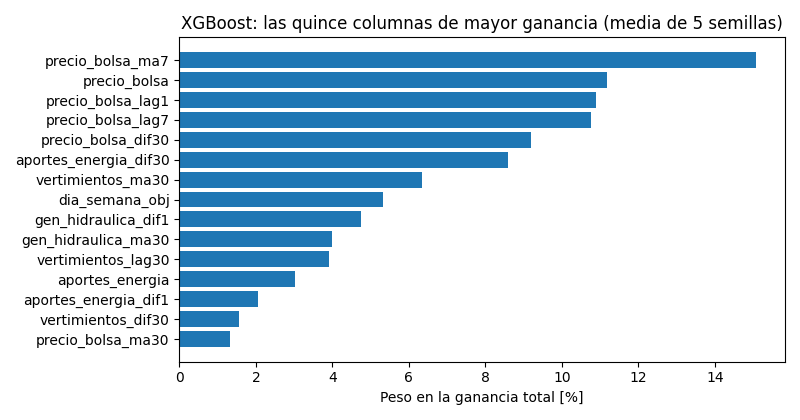

In [10]:
# ============================================================
# 7.1 Importancia por ganancia del modelo base (promedio de las semillas)
# ============================================================
# Un solo ajuste con todo el entrenamiento, que es el modelo del primer bloque de la prueba.
aj_pleno = conjunto_ajuste(origenes[0])
imp_acum = {}
for sem in SEMILLAS:
    mod = construir_modelo(semilla=sem, **PARAMETROS)
    z = np.log(aj_pleno["objetivo"].values / aj_pleno["precio_hoy"].values)
    mod.fit(aj_pleno[COLS], z)
    for col, g in mod.get_booster().get_score(importance_type="gain").items():
        imp_acum[col] = imp_acum.get(col, 0.0) + g / len(SEMILLAS)

importancia = (pd.Series(imp_acum).rename("ganancia").reset_index().rename(columns={"index": "columna"})
               .assign(grupo=lambda d: d["columna"].map(grupo_de))
               .sort_values("ganancia", ascending=False).reset_index(drop=True))
importancia["peso_%"] = 100 * importancia["ganancia"] / importancia["ganancia"].sum()
print(f"Columnas que el modelo llega a usar: {len(importancia)} de {len(COLS)}")
print("\nLas doce de mayor ganancia:")
print(importancia.head(12).round(3).to_string(index=False))

por_grupo = (importancia.groupby("grupo")["peso_%"].sum().sort_values(ascending=False)
             .rename("peso_%").reset_index())
print("\nGanancia agregada por variable de origen:")
print(por_grupo.round(1).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4.2))
top = importancia.head(15).iloc[::-1]
ax.barh(top["columna"], top["peso_%"], color="tab:blue")
ax.set_xlabel("Peso en la ganancia total [%]")
ax.set_title("XGBoost: las quince columnas de mayor ganancia (media de 5 semillas)")
plt.tight_layout()
plt.show();

### 7.2 El techo de los árboles, medido

Esta sección sostiene con números la decisión de la sección 1.3.

In [11]:
# ============================================================
# 7.2 Rango y sesgo del pronóstico según la formulación del objetivo
# ============================================================
t0 = time.time()
pred_rel = np.mean([walk_forward(PARAMETROS, sm, relativo=True) for sm in SEMILLAS], axis=0)
pred_niv = np.mean([walk_forward(PARAMETROS, sm, relativo=False) for sm in SEMILLAS], axis=0)

techo = s.loc[s["fecha"] <= FIN_ENTRENAMIENTO, "objetivo"].max()
diag = pd.DataFrame({
    "objetivo relativo": [pred_rel.min(), pred_rel.mean(), pred_rel.max(),
                          float(np.mean(pred_rel - real_test)), 100 * np.mean(pred_rel < real_test)],
    "objetivo en nivel": [pred_niv.min(), pred_niv.mean(), pred_niv.max(),
                          float(np.mean(pred_niv - real_test)), 100 * np.mean(pred_niv < real_test)],
    "persistencia": [persistencia.min(), persistencia.mean(), persistencia.max(),
                     float(np.mean(persistencia - real_test)), 100 * np.mean(persistencia < real_test)],
    "observado": [real_test.min(), real_test.mean(), real_test.max(), 0.0, np.nan]},
    index=["mínimo", "media", "máximo", "sesgo medio", "% días por debajo"])
print(f"Techo del entrenamiento (máximo del promedio de ventana visto al ajustar): {techo:.1f} COP/kWh\n")
print(diag.round(1).to_string())

print(f"\nEl objetivo en nivel no pasa de {pred_niv.max():.0f} COP/kWh y se queda, en media, "
      f"{abs(np.mean(pred_niv - real_test)):.0f} COP/kWh por debajo de lo observado:")
print("no es que le cueste acertar, es que no puede representar el nivel al que llegó el precio.")
print(f"El objetivo relativo alcanza {pred_rel.max():.0f} y reduce el sesgo a "
      f"{abs(np.mean(pred_rel - real_test)):.0f} COP/kWh, porque el nivel entra multiplicando.")
print(f"\n({time.time() - t0:.0f} s)")

Techo del entrenamiento (máximo del promedio de ventana visto al ajustar): 1147.9 COP/kWh

                   objetivo relativo  objetivo en nivel  persistencia  observado
mínimo                         108.8              113.6         102.8      111.4
media                          444.6              319.8         471.2      466.6
máximo                        2257.5              556.7        2498.8     1730.0
sesgo medio                    -22.1             -146.8           4.6        0.0
% días por debajo               59.0               73.2          55.5        NaN

El objetivo en nivel no pasa de 557 COP/kWh y se queda, en media, 147 COP/kWh por debajo de lo observado:
no es que le cueste acertar, es que no puede representar el nivel al que llegó el precio.
El objetivo relativo alcanza 2258 y reduce el sesgo a 22 COP/kWh, porque el nivel entra multiplicando.

(111 s)


## 8. Evaluación sobre el conjunto de prueba

### 8.1 Qué se evalúa y qué pregunta responde cada variante

| Variante | Qué pregunta responde |
|---|---|
| **Modelo base** — objetivo relativo, reajuste cada 60 días | El resultado del XGBoost en el protocolo del trabajo, el mismo del SARIMAX |
| **Objetivo en nivel** | ¿Cuánto cambia el resultado con la formulación del objetivo? (y la sección 7.2 explica por qué su MAE engaña) |
| **Un solo ajuste** | ¿Aporta algo reajustar el modelo cada dos meses? |
| **Sin el índice ONI** | ¿Se gana algo con el índice climático, o lo que aporta ya está en las variables hidrológicas? |

Todas con las cinco semillas.

In [12]:
# ============================================================
# 8.2 Corrida de las cuatro variantes con las cinco semillas
# ============================================================
VARIANTES = [
    {"clave": "base", "nombre": "XGBoost objetivo relativo, reajuste 60 d",
     "kw": dict(relativo=True, paso=PASO_WFV), "reajuste": PASO_WFV},
    {"clave": "nivel", "nombre": "XGBoost objetivo en nivel, reajuste 60 d",
     "kw": dict(relativo=False, paso=PASO_WFV), "reajuste": PASO_WFV},
    {"clave": "un_ajuste", "nombre": "XGBoost objetivo relativo, un solo ajuste",
     "kw": dict(relativo=True, paso=len(origenes)), "reajuste": None},
    {"clave": "solo_precio", "nombre": "XGBoost objetivo relativo, solo el precio",
     "kw": dict(relativo=True, paso=PASO_WFV, columnas=COLS_SOLO_PRECIO), "reajuste": PASO_WFV},
]

t0 = time.time()
salidas, filas_res = {}, []
for v in VARIANTES:
    preds = [walk_forward(PARAMETROS, sm, **v["kw"]) for sm in SEMILLAS]
    maes = [float(np.mean(np.abs(real_test - p))) for p in preds]
    promedio = np.mean(preds, axis=0)
    salidas[v["clave"]] = {"preds": preds, "promedio": promedio, "maes": maes}
    m = evaluar(v["nombre"], real_test, promedio)
    filas_res.append({**m, "MAE_medio_semillas": float(np.mean(maes)),
                      "desv_semillas": float(np.std(maes)),
                      "reajuste_dias": v["reajuste"]})
    print(f"  {v['nombre']}")
    print(f"     MAE por semilla {[round(x, 2) for x in maes]}  ->  "
          f"media {np.mean(maes):.2f}  desv {np.std(maes):.2f}")
print(f"\n({time.time() - t0:.0f} s)")

  XGBoost objetivo relativo, reajuste 60 d
     MAE por semilla [142.99, 142.97, 143.09, 143.25, 143.24]  ->  media 143.11  desv 0.12


  XGBoost objetivo en nivel, reajuste 60 d
     MAE por semilla [178.99, 180.4, 178.8, 179.7, 178.3]  ->  media 179.24  desv 0.73


  XGBoost objetivo relativo, un solo ajuste
     MAE por semilla [141.08, 140.96, 141.03, 141.0, 141.11]  ->  media 141.04  desv 0.05


  XGBoost objetivo relativo, solo el precio
     MAE por semilla [142.76, 143.16, 143.0, 143.1, 142.68]  ->  media 142.94  desv 0.19

(150 s)


In [13]:
# ============================================================
# 8.3 Resultados sobre los 1.155 orígenes de prueba
# ============================================================
resultados = pd.concat([ref.assign(MAE_medio_semillas=np.nan, desv_semillas=np.nan, reajuste_dias=None),
                        pd.DataFrame(filas_res)], ignore_index=True)
mae_pers = float(ref.loc[0, "MAE"])
resultados["mejora_%"] = 100 * (1 - resultados["MAE"] / mae_pers)

print("Todas las cifras en COP/kWh sobre el precio; la mejora es en MAE frente a la persistencia.\n")
print(resultados[["configuracion", "MAE", "RMSE", "SMAPE", "sesgo", "mejora_%",
                  "MAE_medio_semillas", "desv_semillas"]].round(2).to_string(index=False))

base = resultados[resultados["configuracion"].str.contains("relativo, reajuste")].iloc[0]
print(f"\nMODELO BASE: MAE {base['MAE']:.2f}  RMSE {base['RMSE']:.2f}  SMAPE {base['SMAPE']:.2f}")
print(f"  mejora {base['mejora_%']:.2f} % sobre la persistencia; dispersión entre semillas "
      f"{base['desv_semillas']:.2f} COP/kWh de MAE")

niv = resultados[resultados["configuracion"].str.contains("en nivel")].iloc[0]

# La comparación se DERIVA de la tabla, no se afirma en el texto, porque su dirección depende del
# objetivo: sobre un objetivo puntual esta variante puede tener MEJOR MAE que la relativa, y sobre
# el promedio de la ventana la tiene peor. Una frase que fije la dirección a mano queda
# contradiciendo a la tabla que tiene encima en cuanto cambie el objetivo. Los assert fijan las
# premisas de las que depende el párrafo.
assert niv["MAE"] > base["MAE"], (
    "el párrafo de abajo describe el objetivo en nivel como PEOR en MAE: ya no lo es "
    f"({niv['MAE']:.2f} frente a {base['MAE']:.2f}). Hay que reescribirlo.")
assert niv["sesgo"] < base["sesgo"] - 50, (
    "el párrafo de abajo atribuye el resultado a un sesgo a la baja mucho mayor: "
    f"ya no lo es ({niv['sesgo']:.1f} frente a {base['sesgo']:.1f}).")

print(f"\nEL OBJETIVO EN NIVEL queda por detrás en las TRES métricas: MAE {niv['MAE']:.2f} frente a "
      f"{base['MAE']:.2f}, RMSE {niv['RMSE']:.2f} frente a {base['RMSE']:.2f} y SMAPE "
      f"{niv['SMAPE']:.2f} frente a {base['SMAPE']:.2f}.")
print(f"Ni siquiera supera a la persistencia: {niv['MAE']:.2f} frente a {mae_pers:.2f} de MAE y "
      f"{niv['SMAPE']:.2f} frente a {ref.loc[0, 'SMAPE']:.2f} de SMAPE.")
print(f"La causa es el techo de la sección 7.1: su sesgo es {niv['sesgo']:.1f} COP/kWh, frente a "
      f"{base['sesgo']:.1f} del modelo base.")
print("Un árbol que pronostica el NIVEL no puede salir del rango que vio al entrenarse, y el nivel")
print("del precio se multiplicó por 2,4 entre los dos bloques.")
print("\nY CONVIENE RETENER QUE EL MAE NO SIEMPRE DELATA ESTE DEFECTO. Medida contra un objetivo")
print("PUNTUAL —el precio de un solo día— esta misma variante puede dar MEJOR MAE que la relativa")
print("y ser igual de inservible: con pérdida absoluta el modelo busca la MEDIANA condicional y,")
print("en una distribución con cola derecha, quedarse corto sale barato. El promedio de la ventana")
print("premia menos ese sesgo y por eso aquí el MAE basta, pero lo que delata el techo en los dos")
print("casos es el SESGO y el MÁXIMO del pronóstico. Por eso se reportan los tres juntos.")

Todas las cifras en COP/kWh sobre el precio; la mejora es en MAE frente a la persistencia.

                            configuracion    MAE   RMSE  SMAPE   sesgo  mejora_%  MAE_medio_semillas  desv_semillas
      Referencia: persistencia (P de hoy) 145.66 232.21  30.54    4.56      0.00                 NaN            NaN
      Referencia: media del entrenamiento 292.57 421.42  69.83 -274.66   -100.86                 NaN            NaN
 XGBoost objetivo relativo, reajuste 60 d 143.10 218.48  30.19  -22.07      1.76              143.11           0.12
 XGBoost objetivo en nivel, reajuste 60 d 179.17 284.64  36.79 -146.85    -23.00              179.24           0.73
XGBoost objetivo relativo, un solo ajuste 141.03 215.38  30.12  -30.80      3.18              141.04           0.05
XGBoost objetivo relativo, solo el precio 142.94 215.92  30.30  -38.62      1.87              142.94           0.19

MODELO BASE: MAE 143.10  RMSE 218.48  SMAPE 30.19
  mejora 1.76 % sobre la persistencia; disper

### 8.4 Pronósticos frente a lo observado

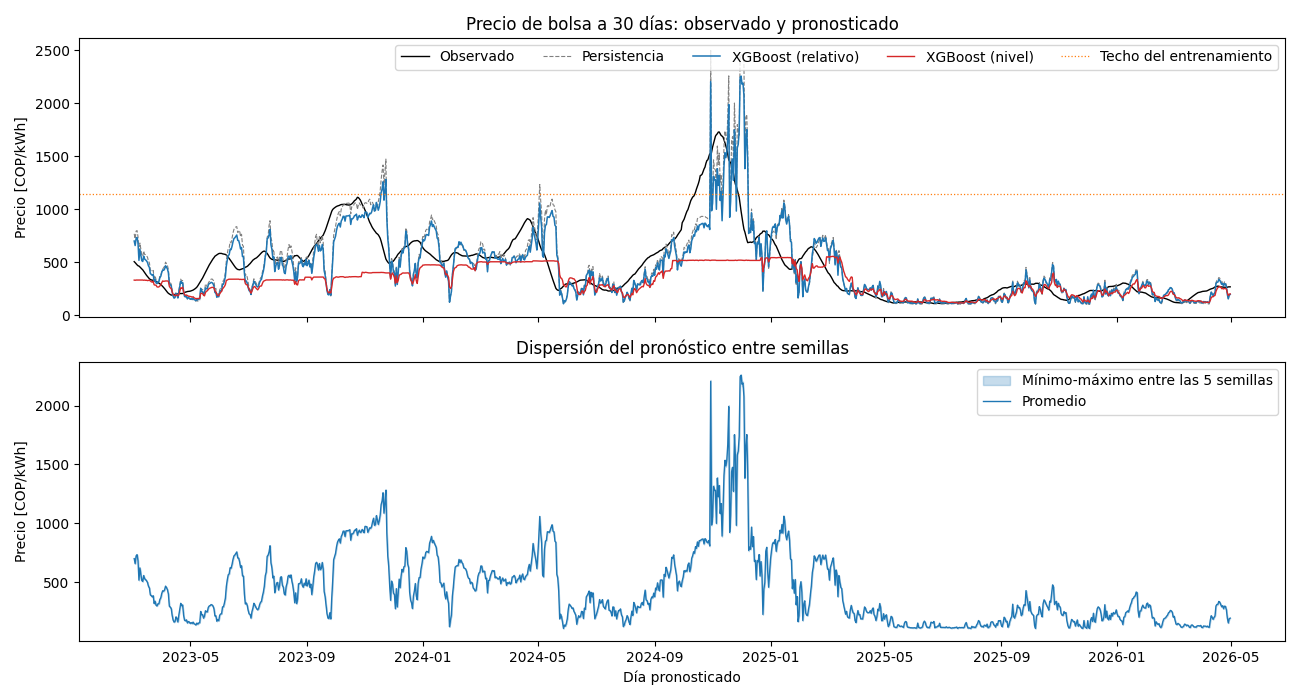

Amplitud media de la banda entre semillas: 3.8 COP/kWh
El pronóstico relativo llega a 2258 COP/kWh y supera el techo del entrenamiento en 36 días,
mientras el objetivo en nivel no pasa de 557: la diferencia no está
en cuántas veces lo supera sino en que una formulación puede y la otra no.


In [14]:
# ============================================================
# 8.4 Serie pronosticada y dispersión entre semillas
# ============================================================
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
axes[0].plot(fecha_obj, real_test, color="black", lw=1.0, label="Observado")
axes[0].plot(fecha_obj, persistencia, color="grey", lw=0.8, ls="--", label="Persistencia")
axes[0].plot(fecha_obj, salidas["base"]["promedio"], color="tab:blue", lw=1.1, label="XGBoost (relativo)")
axes[0].plot(fecha_obj, salidas["nivel"]["promedio"], color="tab:red", lw=1.0, label="XGBoost (nivel)")
axes[0].axhline(s.loc[s["fecha"] <= FIN_ENTRENAMIENTO, "objetivo"].max(), color="tab:orange", lw=0.9,
                ls=":", label="Techo del entrenamiento")
axes[0].set_ylabel("Precio [COP/kWh]")
axes[0].set_title("Precio de bolsa a 30 días: observado y pronosticado")
axes[0].legend(ncol=5, fontsize=10)

banda = np.array(salidas["base"]["preds"])
axes[1].fill_between(fecha_obj, banda.min(axis=0), banda.max(axis=0), color="tab:blue", alpha=0.25,
                     label="Mínimo-máximo entre las 5 semillas")
axes[1].plot(fecha_obj, salidas["base"]["promedio"], color="tab:blue", lw=1.0, label="Promedio")
axes[1].set_ylabel("Precio [COP/kWh]"); axes[1].set_xlabel("Día pronosticado")
axes[1].set_title("Dispersión del pronóstico entre semillas")
axes[1].legend(fontsize=10)
plt.tight_layout()
plt.show();

print(f"Amplitud media de la banda entre semillas: {np.mean(banda.max(axis=0) - banda.min(axis=0)):.1f} COP/kWh")
n_sobre = int((salidas["base"]["promedio"] > s.loc[s["fecha"] <= FIN_ENTRENAMIENTO, "objetivo"].max()).sum())
print(f"El pronóstico relativo llega a {salidas['base']['promedio'].max():.0f} COP/kWh y supera el techo del "
      f"entrenamiento en {n_sobre} día{'s' if n_sobre != 1 else ''},")
print(f"mientras el objetivo en nivel no pasa de {salidas['nivel']['promedio'].max():.0f}: la diferencia no está")
print("en cuántas veces lo supera sino en que una formulación puede y la otra no.")

### 8.5 Error por régimen climático y por año

El trabajo se compromete a reportar el error **segmentado por fase ENSO**, con la fase clasificada por el índice ONI **publicado** en la fecha de pronóstico —no el que se calcula después—, de modo que la etiqueta de cada día podría consultarse….

In [15]:
# ============================================================
# 8.5 MAE por fase ENSO del origen y por año del día pronosticado
# ============================================================
oni_origen = s.set_index("fecha").loc[origenes, "indice_ONI_publicado"].values
fase = np.select([oni_origen >= 0.5, oni_origen <= -0.5], ["El Niño", "La Niña"], default="Neutral")

err = pd.DataFrame({"Persistencia": np.abs(real_test - persistencia),
                    "XGBoost (relativo)": np.abs(real_test - salidas["base"]["promedio"]),
                    "XGBoost (nivel)": np.abs(real_test - salidas["nivel"]["promedio"])})

por_fase = err.groupby(fase).mean().reindex(["El Niño", "Neutral", "La Niña"])
por_fase.insert(0, "n_origenes", pd.Series(fase).value_counts().reindex(por_fase.index).values)
por_fase.insert(1, "precio_medio", pd.Series(real_test).groupby(fase).mean().reindex(por_fase.index).values)
print("MAE [COP/kWh] por régimen ENSO del origen:")
print(por_fase.round(1).to_string())

por_anio = err.groupby(fecha_obj.year).mean()
por_anio.insert(0, "n_dias", pd.Series(fecha_obj.year).value_counts().sort_index().values)
por_anio.insert(1, "precio_medio", pd.Series(real_test).groupby(fecha_obj.year).mean().values)
print("\nMAE [COP/kWh] por año del día pronosticado:")
print(por_anio.round(1).to_string())

ventaja = (1 - por_fase["XGBoost (relativo)"] / por_fase["Persistencia"]) * 100
print("\nVentaja del modelo base sobre la persistencia, por fase [%]:")
print(ventaja.round(1).to_string())

MAE [COP/kWh] por régimen ENSO del origen:
         n_origenes  precio_medio  Persistencia  XGBoost (relativo)  XGBoost (nivel)
El Niño         335         599.3         163.3               161.5            226.3
Neutral         666         453.5         149.9               149.4            184.1
La Niña         154         234.9          88.8                76.0             55.5

MAE [COP/kWh] por año del día pronosticado:
       n_dias  precio_medio  Persistencia  XGBoost (relativo)  XGBoost (nivel)
fecha                                                                         
2023      304         576.0         163.5               163.5            266.1
2024      366         670.9         213.6               209.8            262.4
2025      365         254.9          88.1                85.4             64.1
2026      120         210.4          68.3                63.4             55.1

Ventaja del modelo base sobre la persistencia, por fase [%]:
El Niño     1.1
Neutral     0.4
La N

### 8.6 Cómo crece el error con el horizonte

La estrategia directa de la sección 1.4 no produce la trayectoria intermedia: el modelo está entrenado para pronosticar exactamente a treinta días.

Trayectoria: 1155 orígenes x 30 horizontes, promediada sobre 5 semillas  (1569 s)
  [resultados_modelos.csv] 6_XGBoost_modelo_base: se retiran 18 filas de corridas anteriores de este notebook

=== TODOS LOS PARES origen-horizonte ===
                                                                   configuracion    MAE   RMSE  SMAPE  razon_vs_persistencia
                                             Referencia: persistencia (P de hoy) 178.37 291.68  37.07                   1.00
XGBoost profundidad 1, 200 árboles, mcw 100, tasa 0,02 (trayectoria, 5 semillas) 175.59 278.63  37.09                   0.98

=== PROMEDIO DEL MES ===
                                                                   configuracion    MAE   RMSE  SMAPE  razon_vs_persistencia
                                             Referencia: persistencia (P de hoy) 145.66 232.21  30.54                   1.00
XGBoost profundidad 1, 200 árboles, mcw 100, tasa 0,02 (trayectoria, 5 semillas) 143.17 218.09  30.40              


  [resultados_modelos.csv] 6 filas de las tres lecturas
 horizonte  MAE_modelo  MAE_persistencia    n  razon
         1      52.076            53.083 1155  0.981
         2      73.377            76.106 1155  0.964
         3      87.893            90.961 1155  0.966
         7     131.687           133.389 1155  0.987
        14     181.049           180.934 1155  1.001
        21     209.098           211.559 1155  0.988
        30     232.745           239.273 1155  0.973


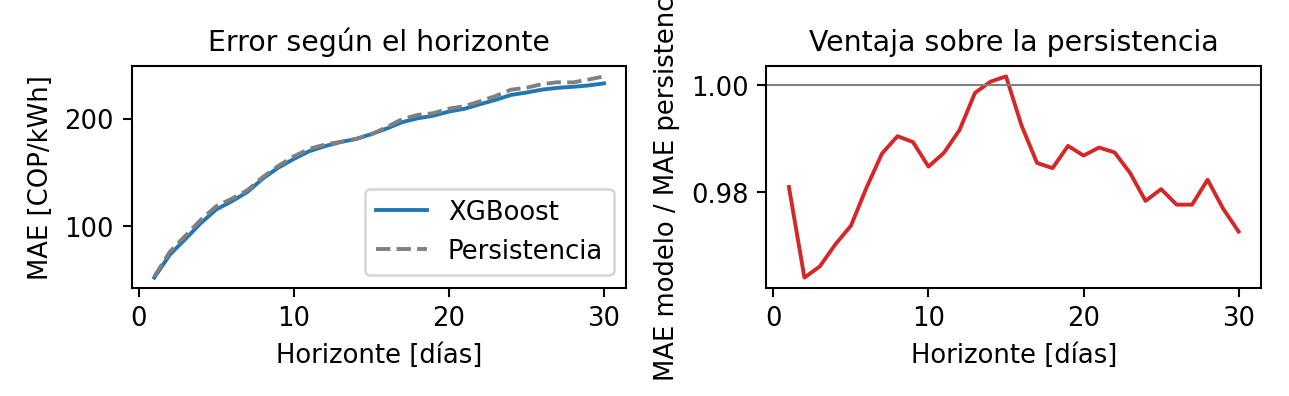


La ventaja sobre la persistencia NO crece con el horizonte: la razón oscila entre 0.964 (h = 2) y 1.002 (h = 15),
y en 3 de los 30 horizontes el modelo apenas empata con ella.
La forma de la curva no es la que cabría esperar. Si el aporte del modelo fuera explicar lo que
la inercia del precio no explica, la ventaja debería CRECER con el horizonte, porque P(t) pierde
valor como pronóstico a medida que t + h se aleja. Lo que se ve es otra cosa: la ventaja es
mayor a dos y tres días, se pierde hacia la mitad del horizonte y reaparece al final.
Dicho de otro modo, el modelo gana donde la persistencia ya es buena y empata donde sería más
útil ganar. Es el mismo patrón que da la segmentación por fase de la sección 8.5, donde la ventaja
se concentra en La Niña y es indistinguible de cero en los días neutrales.

(1569 s)


In [16]:
# ============================================================
# 8.6 MAE por horizonte (1 a 30 días), un modelo entrenado para cada uno
# ============================================================
t0 = time.time()

# Matriz (orígenes × 30) con el precio observado de cada día de cada ventana, tomada de la misma
# serie `PRECIO_DIARIO` con la que se construyen los objetivos: el pronóstico y la referencia
# contra la que se mide vienen de una sola fuente.
REALES = np.column_stack([PRECIO_DIARIO.reindex(origenes + pd.Timedelta(days=h)).values
                          for h in range(1, HORIZONTE + 1)])
assert not np.isnan(REALES).any(), "faltan precios observados en la matriz de reales"

# La trayectoria del modelo: un ajuste por horizonte y por semilla, promediado entre semillas.
# Un árbol no genera trayectorias como el SARIMAX, de modo que hay que entrenar uno por horizonte.
# Son 30 x 5 = 150 corridas de validación progresiva; es el precio de reportar la curva y las
# métricas con el mismo protocolo en vez de la curva con una semilla y las métricas con cinco.
# Se guarda la trayectoria DE CADA SEMILLA y no solo su promedio, porque la figura del
# pronostico dibuja la banda entre semillas y tiene que dibujar la del estimador que se publica.
TRAY_SEMILLA = [np.column_stack([walk_forward(PARAMETROS, sm, relativo=True, paso=PASO_WFV,
                                              horizonte=h)
                                 for h in range(1, HORIZONTE + 1)])
                for sm in SEMILLAS]
TRAY = np.mean(TRAY_SEMILLA, axis=0)
assert TRAY.shape == REALES.shape, f"trayectoria {TRAY.shape} y reales {REALES.shape}"
# Sin NaN: `lecturas` descarta todo origen con un hueco en cualquiera de sus 30 columnas, de modo
# que un puñado de NaN al final de la serie reduciría el conjunto medido sin que nada lo avisara
# y las métricas dejarían de ser comparables con las del notebook 5.
assert not np.isnan(TRAY).any(), "la trayectoria tiene huecos: las lecturas perderían orígenes"
print(f"Trayectoria: {TRAY.shape[0]} orígenes x {TRAY.shape[1]} horizontes, "
      f"promediada sobre {len(SEMILLAS)} semillas  ({time.time() - t0:.0f} s)")

PERSIST = np.repeat(persistencia[:, None], HORIZONTE, axis=1)      # repite P(t) los 30 días
filas_h = []
for k in range(HORIZONTE):
    valido = ~np.isnan(TRAY[:, k]) & ~np.isnan(REALES[:, k])
    filas_h.append({"horizonte": k + 1,
                    "MAE_modelo": float(np.mean(np.abs(REALES[valido, k] - TRAY[valido, k]))),
                    "MAE_persistencia": float(np.mean(np.abs(REALES[valido, k] - persistencia[valido]))),
                    "n": int(valido.sum())})
por_horizonte = pd.DataFrame(filas_h)
por_horizonte["razon"] = por_horizonte["MAE_modelo"] / por_horizonte["MAE_persistencia"]

# ------------------------------------------------------------------
# Las tres lecturas de esta misma trayectoria
# ------------------------------------------------------------------
from _resultados import lecturas as tres_lecturas, registrar as registrar_lectura
from _resultados import olvidar

# Primer registro del notebook: se retiran las filas de corridas anteriores de este mismo notebook.
# Va aquí y no en la celda final porque la celda final escribe DESPUÉS, y llamarlo allí borraría lo
# que esta sección acaba de registrar.
olvidar("6_XGBoost_modelo_base")

LECTURAS = {"Referencia: persistencia (P de hoy)": tres_lecturas(PERSIST, REALES),
            f"XGBoost {MEJOR_NOMBRE} (trayectoria, {len(SEMILLAS)} semillas)":
                tres_lecturas(TRAY, REALES)}
ETIQUETAS = {"pares_30d": "TODOS LOS PARES origen-horizonte",
             "promedio_30d": "PROMEDIO DEL MES",
             "dia_30": "SOLO EL DÍA 30"}
tablas_lect = {}
for clave, etiqueta in ETIQUETAS.items():
    t = pd.DataFrame([dict(configuracion=n, **v[clave]) for n, v in LECTURAS.items()])
    t["razon_vs_persistencia"] = t["MAE"] / t.loc[0, "MAE"]
    tablas_lect[clave] = t
    print(f"\n=== {etiqueta} ===")
    print(t.round(2).to_string(index=False))

# Las tres lecturas tienen que salir de los 1.155 orígenes, los mismos del notebook 5.
n_usados = int((~np.isnan(TRAY).any(axis=1) & ~np.isnan(REALES).any(axis=1)).sum())
assert n_usados == len(origenes), \
    f"las lecturas usan {n_usados} de {len(origenes)} orígenes: no son comparables con el notebook 5"

for clave, t in tablas_lect.items():
    for _, fila in t.iterrows():
        nombre = fila["configuracion"]
        es_ref = nombre.startswith("Referencia")
        registrar_lectura(notebook="6_XGBoost_modelo_base",
                          familia="Referencia" if es_ref else "Machine Learning",
                          modelo=nombre if es_ref else "XGBoost",
                          objetivo=clave,
                          configuracion="regla trivial" if es_ref else nombre,
                          particion="65/15/20 por fecha", embargo_dias=dias_embargo,
                          reajuste_dias=None if es_ref else PASO_WFV,
                          semilla=None, bloque="prueba",
                          n_obs=len(origenes) * (HORIZONTE if clave == "pares_30d" else 1),
                          MAE=fila["MAE"], RMSE=fila["RMSE"], SMAPE=fila["SMAPE"], verbose=False)
print(f"\n  [resultados_modelos.csv] {sum(len(t) for t in tablas_lect.values())} filas de las "
      f"tres lecturas")
print(por_horizonte.loc[por_horizonte["horizonte"].isin([1, 2, 3, 7, 14, 21, 30])].round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(ANCHO_PAGINA, alto_pagina(13, 4)))
axes[0].plot(por_horizonte["horizonte"], por_horizonte["MAE_modelo"], label="XGBoost")
axes[0].plot(por_horizonte["horizonte"], por_horizonte["MAE_persistencia"], ls="--", color="grey",
             label="Persistencia")
axes[0].set_xlabel("Horizonte [días]"); axes[0].set_ylabel("MAE [COP/kWh]")
axes[0].set_title("Error según el horizonte"); axes[0].legend()
axes[1].plot(por_horizonte["horizonte"], por_horizonte["razon"], color="tab:red")
axes[1].axhline(1, color="grey", lw=0.8)
axes[1].set_xlabel("Horizonte [días]"); axes[1].set_ylabel("MAE modelo / MAE persistencia")
axes[1].set_title("Ventaja sobre la persistencia")
a_escala(fig)
plt.tight_layout()
plt.show();

peor_h = por_horizonte.loc[por_horizonte["razon"].idxmax()]
mejor_h = por_horizonte.loc[por_horizonte["razon"].idxmin()]
print(f"\nLa ventaja sobre la persistencia NO crece con el horizonte: la razón oscila entre "
      f"{mejor_h['razon']:.3f} (h = {int(mejor_h['horizonte'])}) y {peor_h['razon']:.3f} "
      f"(h = {int(peor_h['horizonte'])}),")
print(f"y en {int((por_horizonte['razon'] >= 0.995).sum())} de los {HORIZONTE} horizontes el modelo "
      "apenas empata con ella.")
print("La forma de la curva no es la que cabría esperar. Si el aporte del modelo fuera explicar lo que")
print("la inercia del precio no explica, la ventaja debería CRECER con el horizonte, porque P(t) pierde")
print("valor como pronóstico a medida que t + h se aleja. Lo que se ve es otra cosa: la ventaja es")
print("mayor a dos y tres días, se pierde hacia la mitad del horizonte y reaparece al final.")
print("Dicho de otro modo, el modelo gana donde la persistencia ya es buena y empata donde sería más")
print("útil ganar. Es el mismo patrón que da la segmentación por fase de la sección 8.5, donde "
      "la ventaja")
print("se concentra en La Niña y es indistinguible de cero en los días neutrales.")
print(f"\n({time.time() - t0:.0f} s)")

### 8.7 Contra la familia estadística

Esta es la comparación que responde a la pregunta del trabajo, y es legítima porque las dos familias se midieron sobre **los mismos 1.155 orígenes, con el mismo conjunto de variables, el mismo embargo y la misma política de reajuste**.

In [17]:
# ============================================================
# 8.7 XGBoost frente al SARIMAX del notebook 5
# ============================================================
sar = pd.read_csv(os.path.join(PROC, "5_predicciones_sarimax.csv"),
                  parse_dates=["fecha", "fecha_objetivo"])
assert len(sar) == len(origenes) and (pd.DatetimeIndex(sar["fecha"]) == origenes).all(), \
    "El SARIMAX no se evaluó sobre los mismos orígenes"
assert np.allclose(sar["real"].values, real_test), "La serie real no coincide con la del notebook 5"

cols_sar = [c for c in sar.columns if c.startswith("SARIMA") and "[" not in c]
mejor_sar = min(cols_sar, key=lambda c: np.mean(np.abs(real_test - sar[c].values)))
pred_sar = sar[mejor_sar].values
print(f"Mejor configuración del SARIMAX por MAE: {mejor_sar}\n")

comparativa = pd.DataFrame([
    evaluar("Referencia: persistencia", real_test, persistencia),
    evaluar(f"Estadística — {mejor_sar}", real_test, pred_sar),
    evaluar("ML clásico — XGBoost (modelo base)", real_test, salidas["base"]["promedio"]),
])
comparativa["mejora_%"] = 100 * (1 - comparativa["MAE"] / mae_pers)
print(comparativa.round(2).to_string(index=False))

# ¿Hay alguna fase o año en que el XGBoost gane?
err_cmp = pd.DataFrame({"Persistencia": np.abs(real_test - persistencia),
                        "SARIMAX": np.abs(real_test - pred_sar),
                        "XGBoost": np.abs(real_test - salidas["base"]["promedio"])})
cmp_fase = err_cmp.groupby(fase).mean().reindex(["El Niño", "Neutral", "La Niña"])
cmp_anio = err_cmp.groupby(fecha_obj.year).mean()
print("\nMAE por fase ENSO:")
print(cmp_fase.round(1).to_string())
print("\nMAE por año del día pronosticado:")
print(cmp_anio.round(1).to_string())

gana_xgb_fase = (cmp_fase["XGBoost"] < cmp_fase["SARIMAX"]).sum()
gana_xgb_anio = (cmp_anio["XGBoost"] < cmp_anio["SARIMAX"]).sum()
print(f"\nFases en que el XGBoost supera al SARIMAX: {gana_xgb_fase} de {len(cmp_fase)}")
print(f"Años en que el XGBoost supera al SARIMAX: {gana_xgb_anio} de {len(cmp_anio)}")
print("\nLas dos familias superan a la persistencia en las tres fases y en los cuatro años, de modo que")
print("ninguna de las dos debe su ventaja a un tramo concreto del periodo de prueba.")

Mejor configuración del SARIMAX por MAE: SARIMAX (2,1,1)(1,0,0,7) log + sistema, invertibilidad impuesta

                                                                configuracion    MAE   RMSE  SMAPE  sesgo  mejora_%
                                                     Referencia: persistencia 145.66 232.21  30.54   4.56      0.00
Estadística — SARIMAX (2,1,1)(1,0,0,7) log + sistema, invertibilidad impuesta 136.53 206.86  28.42 -21.90      6.27
                                           ML clásico — XGBoost (modelo base) 143.10 218.48  30.19 -22.07      1.76

MAE por fase ENSO:
         Persistencia  SARIMAX  XGBoost
El Niño         163.3    152.3    161.5
Neutral         149.9    144.4    149.4
La Niña          88.8     68.2     76.0

MAE por año del día pronosticado:
       Persistencia  SARIMAX  XGBoost
fecha                                
2023          163.5    150.2    163.5
2024          213.6    205.8    209.8
2025           88.1     82.3     85.4
2026           68.3     5

## 9. Guardado de resultados

In [18]:
# ============================================================
# 8.8 Las métricas del entrenamiento, junto a las de la prueba
# ============================================================
# QUÉ FALTABA. Hasta aquí el notebook informa del error sobre la prueba y, en la sección 6, de la
# razón frente a la persistencia en los cinco pliegues de validación. Falta la otra mitad de la
# pregunta: cuánto acierta el modelo sobre los datos con los que se ajustó. Sin esa cifra el
# control del sobreajuste —árboles de uno o dos cortes, hojas de cien observaciones, submuestreo—
# se puede argumentar pero no medir.
#
# CÓMO SE MIDE. Con el mismo rasero que la prueba: trayectoria de treinta días desde cada origen,
# precio reconstruido en COP/kWh y las tres lecturas. Un árbol no genera la trayectoria solo, de
# modo que hacen falta treinta modelos, uno por horizonte, como en la sección 8.6; los treinta se
# ajustan sobre el MISMO conjunto de orígenes para que las treinta columnas midan lo mismo.
from _entrenamiento import tabla_brecha, registrar_brecha, leer_brecha

# El conjunto en muestra: los orígenes del entrenamiento cuya ventana de treinta días ya había
# terminado cuando empieza la prueba. Es lo que ve el ajuste que produce el primer pronóstico.
_d30 = datos_a_horizonte(HORIZONTE)
_emb30 = (_d30["fecha"] > FIN_ENTRENAMIENTO) & (_d30["fecha"] < INICIO_PRUEBA)
EN_MUESTRA = _d30[(_d30["fecha_objetivo"] < origenes[0]) & ~_emb30]
FECHAS_EN = pd.DatetimeIndex(EN_MUESTRA["fecha"].values)
assert FECHAS_EN.max() <= FIN_ENTRENAMIENTO, "el bloque en muestra entra en el embargo"

POR_H = {h: datos_a_horizonte(h) for h in range(1, HORIZONTE + 1)}
FILAS_EN = {h: d[d["fecha"].isin(FECHAS_EN)] for h, d in POR_H.items()}
assert all(len(f) == len(FECHAS_EN) for f in FILAS_EN.values()), \
    "algún horizonte no cubre los mismos orígenes que los demás"

t0 = time.time()
TRAY_ENTREN = np.mean([np.column_stack([
    ajustar_predecir(construir_modelo(semilla=sm, **PARAMETROS),
                     FILAS_EN[h], FILAS_EN[h], COLS, relativo=True)
    for h in range(1, HORIZONTE + 1)]) for sm in SEMILLAS], axis=0)
print(f"En muestra: {len(FECHAS_EN)} origenes de {FECHAS_EN.min().date()} a "
      f"{FECHAS_EN.max().date()}, {HORIZONTE} horizontes x {len(SEMILLAS)} semillas "
      f"({time.time() - t0:.0f} s)")

REALES_EN = np.column_stack([PRECIO_DIARIO.reindex(FECHAS_EN + pd.Timedelta(days=h)).values
                             for h in range(1, HORIZONTE + 1)])
assert not np.isnan(REALES_EN).any(), "faltan precios observados en el bloque en muestra"
PERS_EN = np.repeat(EN_MUESTRA["precio_hoy"].values[:, None], HORIZONTE, axis=1)

BRECHA = tabla_brecha({"entrenamiento": (TRAY_ENTREN, REALES_EN, PERS_EN),
                       "prueba": (TRAY, REALES, PERSIST)})
print()
print(BRECHA.round(3).to_string(index=False))
print()
print(leer_brecha(BRECHA))

registrar_brecha(BRECHA, notebook="6_XGBoost_modelo_base", familia="Machine Learning",
                 modelo="XGBoost",
                 configuracion=f"XGBoost {MEJOR_NOMBRE} (trayectoria, {len(SEMILLAS)} semillas)",
                 particion="65/15/20 por fecha", embargo_dias=dias_embargo,
                 reajuste_dias=None, verbose=True)

BRECHA.to_csv(os.path.join(PROC, "6_brecha_entrenamiento_prueba.csv"), index=False)
print(f"\n  [datasets/procesado] 6_brecha_entrenamiento_prueba.csv")

# ------------------------------------------------------------
# El error de CADA ventana de treinta días
# ------------------------------------------------------------
# La tabla de arriba resume cada bloque en una cifra, y una cifra no dice si el modelo acierta
# de forma pareja o alterna tramos buenos y malos. Se guarda el error de cada pronóstico por
# separado, con su persistencia, para poder ver cómo evoluciona a lo largo del periodo.
from _entrenamiento import error_por_origen

DETALLE = error_por_origen({"entrenamiento": (TRAY_ENTREN, REALES_EN, PERS_EN, FECHAS_EN),
                            "prueba": (TRAY, REALES, PERSIST, origenes)})
DETALLE.to_csv(os.path.join(PROC, "6_error_por_origen.csv"), index=False)
print(f"\n  [datasets/procesado] 6_error_por_origen.csv  "
      f"({len(DETALLE)} orígenes: "
      f"{(DETALLE['bloque'] == 'entrenamiento').sum()} en muestra y "
      f"{(DETALLE['bloque'] == 'prueba').sum()} de prueba)")
print(DETALLE.groupby("bloque")[["MAE", "MAE_persistencia", "razon"]].median().round(3)
      .to_string())

En muestra: 4568 origenes de 2010-06-30 a 2022-12-31, 30 horizontes x 5 semillas (74 s)

       bloque  n_origenes     objetivo     MAE    RMSE  SMAPE  MAE_persistencia  razon
entrenamiento        4568    pares_30d  48.397 103.377 22.763            52.768  0.917
       prueba        1155    pares_30d 175.592 278.633 37.090           178.369  0.984
entrenamiento        4568 promedio_30d  40.947  82.003 19.220            45.461  0.901
       prueba        1155 promedio_30d 143.165 218.094 30.395           145.662  0.983
entrenamiento        4568       dia_30  63.438 129.469 29.430            71.760  0.884
       prueba        1155       dia_30 232.745 339.326 48.669           239.273  0.973

El MAE pasa de 40.95 en el entrenamiento a 143.17 en la prueba, 3.50 veces mayor. La
persistencia pasa de 45.46 a 145.66 sobre los mismos orígenes, 3.20 veces, y la razón
frente a ella pasa de 0.901 a 0.983.
Descontado lo que sube la persistencia, queda un deterioro de 9 % en la razón:
hay brecha, pe

Arboles de la configuracion elegida: 200
Cortes evaluados: [10, 25, 50, 100, 150, 200]



Curva de aprendizaje, promediada sobre los 5 pliegues (3 s):

 arboles  MAE_ajuste  MAE_validacion  razon_ajuste  razon_validacion
      10      36.578          51.481         0.981             0.989
      25      35.587          50.427         0.954             0.972
      50      34.677          49.750         0.928             0.960
     100      33.640          49.124         0.898             0.948
     150      33.089          48.890         0.882             0.943
     200      32.676          48.644         0.870             0.937

La razon frente a la persistencia es minima en el AJUSTE con 200 arboles y en la VALIDACION con 200.
  Las dos curvas tienen su mínimo en el mismo corte: con esta configuración el número de
  árboles no llega a separar el ajuste de la generalización.


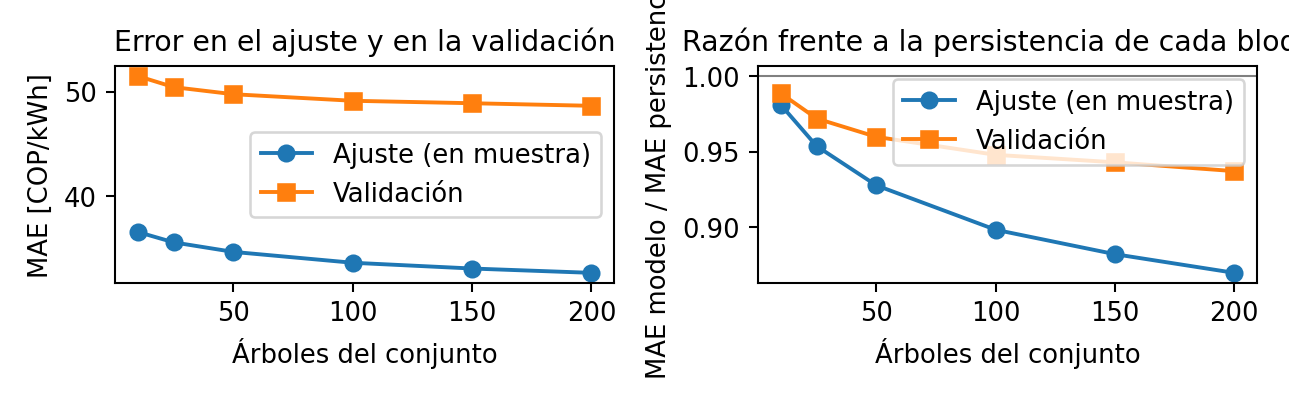


  [datasets/procesado] 6_curva_aprendizaje.csv


In [19]:
# ============================================================
# 8.9 La curva de aprendizaje: ajuste contra validación, árbol a árbol
# ============================================================
# El equivalente del número de épocas de una red es aquí el número de árboles, y es la palanca que
# decide cuánto puede memorizar el modelo. A diferencia de la red, no hace falta reentrenar para
# ver la curva: `iteration_range` evalúa el conjunto truncado a los primeros k árboles.
#
# Se mide sobre el AJUSTE y sobre la VALIDACIÓN de cada pliegue. Si la de ajuste baja mientras la
# de validación sube, lo que el modelo gana añadiendo árboles es memoria.
CORTES_ARBOLES = sorted({k for k in (10, 25, 50, 100, 150, 200, 300, 400)
                         if k < PARAMETROS.get("n_estimators", 100)}
                        | {PARAMETROS.get("n_estimators", 100)})
print(f"Arboles de la configuracion elegida: {PARAMETROS.get('n_estimators', 100)}")
print(f"Cortes evaluados: {CORTES_ARBOLES}")


def curva_arboles(fin_ajuste, v_ini, v_fin, semilla=42):
    """MAE del promedio del mes sobre el ajuste y sobre la validación, en cada corte de árboles."""
    aj, va = datos_pliegue(fin_ajuste, v_ini, v_fin)
    modelo = construir_modelo(semilla=semilla, **PARAMETROS)
    modelo.fit(aj[COLS], np.log(aj["objetivo"].values / aj["precio_hoy"].values))
    per = {"ajuste": float(np.mean(np.abs(aj["objetivo"].values - aj["precio_hoy"].values))),
           "validacion": float(np.mean(np.abs(va["objetivo"].values - va["precio_hoy"].values)))}
    filas = []
    for k in CORTES_ARBOLES:
        p_aj = aj["precio_hoy"].values * np.exp(modelo.predict(aj[COLS], iteration_range=(0, k)))
        p_va = va["precio_hoy"].values * np.exp(modelo.predict(va[COLS], iteration_range=(0, k)))
        m_aj = float(np.mean(np.abs(aj["objetivo"].values - p_aj)))
        m_va = float(np.mean(np.abs(va["objetivo"].values - p_va)))
        filas.append({"arboles": k, "MAE_ajuste": m_aj, "MAE_validacion": m_va,
                      "razon_ajuste": m_aj / per["ajuste"],
                      "razon_validacion": m_va / per["validacion"]})
    return pd.DataFrame(filas)


t0 = time.time()
CURVA = pd.concat([curva_arboles(*pl) for pl in PLIEGUES]).groupby("arboles").mean().reset_index()
print(f"\nCurva de aprendizaje, promediada sobre los {len(PLIEGUES)} pliegues "
      f"({time.time() - t0:.0f} s):\n")
print(CURVA.round(3).to_string(index=False))

# SE LEE LA RAZÓN, NO EL MAE CRUDO. Los cinco pliegues caen en tramos de distinto nivel de precio
# y promediar sus MAE pondera los caros; la razón frente a la persistencia de cada pliegue es la
# cantidad con la que se eligió la configuración. Si las dos no apuntan al mismo corte, se dice.
_c = CURVA.set_index("arboles")
_opt_aj = int(_c["razon_ajuste"].idxmin())
_opt_val = int(_c["razon_validacion"].idxmin())
_opt_mae = int(_c["MAE_validacion"].idxmin())
print(f"\nLa razon frente a la persistencia es minima en el AJUSTE con {_opt_aj} arboles "
      f"y en la VALIDACION con {_opt_val}.")
if _opt_mae != _opt_val:
    print(f"  El MAE crudo de validacion, en cambio, es minimo con {_opt_mae}: entre los dos "
          f"cortes hay\n  "
          f"{abs(_c.loc[_opt_mae, 'MAE_validacion'] - _c.loc[_opt_val, 'MAE_validacion']):.2f}"
          f" COP/kWh de diferencia, y no coinciden porque cada pliegue\n  tiene su propio nivel "
          f"de persistencia.")
if _opt_aj > _opt_val:
    print(f"  A partir de {_opt_val} el modelo sigue mejorando sobre lo que ya vio y empeora "
          f"sobre lo que no:\n  eso es sobreajuste, y es lo que acota el tamaño del conjunto.")
else:
    print("  Las dos curvas tienen su mínimo en el mismo corte: con esta configuración el "
          "número de\n  árboles no llega a separar el ajuste de la generalización.")

fig, axes = plt.subplots(1, 2, figsize=(ANCHO_PAGINA, alto_pagina(13, 4)))
axes[0].plot(CURVA["arboles"], CURVA["MAE_ajuste"], marker="o", label="Ajuste (en muestra)")
axes[0].plot(CURVA["arboles"], CURVA["MAE_validacion"], marker="s", label="Validación")
axes[0].set_xlabel("Árboles del conjunto"); axes[0].set_ylabel("MAE [COP/kWh]")
axes[0].set_title("Error en el ajuste y en la validación"); axes[0].legend()
axes[1].plot(CURVA["arboles"], CURVA["razon_ajuste"], marker="o", label="Ajuste (en muestra)")
axes[1].plot(CURVA["arboles"], CURVA["razon_validacion"], marker="s", label="Validación")
axes[1].axhline(1, color="grey", lw=0.8)
axes[1].set_xlabel("Árboles del conjunto")
axes[1].set_ylabel("MAE modelo / MAE persistencia")
axes[1].set_title("Razón frente a la persistencia de cada bloque"); axes[1].legend()
a_escala(fig)
plt.tight_layout()
plt.show()

CURVA.to_csv(os.path.join(PROC, "6_curva_aprendizaje.csv"), index=False)
print(f"\n  [datasets/procesado] 6_curva_aprendizaje.csv")


In [20]:
# ============================================================
# 9. Salidas
# ============================================================
resultados.to_csv(os.path.join(PROC, "6_metricas_xgboost.csv"), index=False)
por_horizonte.to_csv(os.path.join(PROC, "6_error_por_horizonte_xgb.csv"), index=False)
importancia.to_csv(os.path.join(PROC, "6_importancia_xgboost.csv"), index=False)

pred_guardar = pd.DataFrame({"fecha": origenes, "fecha_objetivo": fecha_obj,
                             "real": real_test, "persistencia": persistencia})
for v in VARIANTES:
    pred_guardar[v["nombre"]] = salidas[v["clave"]]["promedio"]
for k, sm in enumerate(SEMILLAS):           # las cinco corridas del modelo base, para la dispersión
    pred_guardar[f"base_semilla_{sm}"] = salidas["base"]["preds"][k]
# LA CONFIGURACION QUE PUBLICA EL DOCUMENTO ES LA DE LA TRAYECTORIA, y hasta aqui no salia de
# este cuaderno: el archivo solo llevaba el estimador DIRECTO, el que entrena un modelo contra el
# promedio de los treinta dias. Son dos estimadores distintos del mismo numero —143,17 el primero
# y 143,10 el segundo— y el cuaderno 9 leia el segundo para comparar entre familias, de modo que
# su tabla por fase ENSO y su prueba de Diebold-Mariano describian un modelo que no era el de la
# tabla de errores. El nombre de la columna se construye con la MISMA expresion con que la seccion
# 8.6 la registra en el consolidado, para que no puedan divergir.
COL_TRAYECTORIA = f"XGBoost {MEJOR_NOMBRE} (trayectoria, {len(SEMILLAS)} semillas)"
pred_guardar[COL_TRAYECTORIA] = TRAY.mean(axis=1)
for sm, t_sm in zip(SEMILLAS, TRAY_SEMILLA):
    pred_guardar[f"trayectoria_semilla_{sm}"] = t_sm.mean(axis=1)
# El promedio de las cinco trayectorias por fila tiene que dar el MAE que se registro con ellas.
_mae_tray = float(np.mean(np.abs(real_test - pred_guardar[COL_TRAYECTORIA].to_numpy())))
assert abs(_mae_tray - tablas_lect["promedio_30d"].iloc[1]["MAE"]) < 1e-9, (
    f"la columna de la trayectoria da {_mae_tray:.4f} y la seccion 8.6 registro "
    f"{tablas_lect['promedio_30d'].iloc[1]['MAE']:.4f}")
print(f"Columna de la trayectoria: MAE {_mae_tray:.2f} COP/kWh, el de la tabla de errores.")

pred_guardar.to_csv(os.path.join(PROC, "6_predicciones_xgboost.csv"), index=False)

# Al consolidado de las cinco familias, con las condiciones que hacen comparable una fila con otra.
#
# LAS REFERENCIAS NO SE REGISTRAN AQUI. Las escribio ya 5_SARIMAX_modelo_base y son las mismas por
# construccion: la clave de deduplicacion de registrar() incluye el notebook, de modo que volver a
# escribirlas crearia una copia por cada notebook de modelo —cinco al terminar el trabajo— y la
# tabla comparativa del documento tendria cinco filas identicas de persistencia. El assert de la
# seccion 4 ya comprueba que coinciden, que es lo que habia que garantizar.
from _resultados import registrar

for v, fila in zip(VARIANTES, filas_res):
    registrar(notebook="6_XGBoost_modelo_base", familia="Machine Learning", modelo="XGBoost",
              objetivo="promedio_30d",          # el precio medio de los 30 días siguientes
              configuracion=f"{MEJOR_NOMBRE} | {v['nombre']}", particion="65/15/20 por fecha",
              embargo_dias=dias_embargo, reajuste_dias=v["reajuste"], semilla=None,
              bloque="prueba", n_obs=len(origenes),
              MAE=fila["MAE"], RMSE=fila["RMSE"], SMAPE=fila["SMAPE"],
              notas=f"promedio de {len(SEMILLAS)} semillas; MAE medio {fila['MAE_medio_semillas']:.2f}, "
                    f"desv {fila['desv_semillas']:.2f}")

# Y las cinco semillas del modelo base por separado, para que la dispersión quede en el registro.
for sm, mae_sm in zip(SEMILLAS, salidas["base"]["maes"]):
    m = evaluar("", real_test, salidas["base"]["preds"][SEMILLAS.index(sm)])
    registrar(notebook="6_XGBoost_modelo_base", familia="Machine Learning", modelo="XGBoost",
              objetivo="promedio_30d",
              configuracion=f"{MEJOR_NOMBRE} | objetivo relativo, reajuste 60 d",
              particion="65/15/20 por fecha", embargo_dias=dias_embargo, reajuste_dias=PASO_WFV,
              semilla=sm, bloque="prueba", n_obs=len(origenes),
              MAE=m["MAE"], RMSE=m["RMSE"], SMAPE=m["SMAPE"], notas="corrida individual")

carpeta_modelo = os.path.join(abspath, "models", "baseline", "XGBoost")
os.makedirs(carpeta_modelo, exist_ok=True)
mod_final = construir_modelo(semilla=SEMILLAS[0], **PARAMETROS)
aj_final = conjunto_ajuste(origenes[-1])
mod_final.fit(aj_final[COLS], np.log(aj_final["objetivo"].values / aj_final["precio_hoy"].values))
mod_final.save_model(os.path.join(carpeta_modelo, "xgboost_base.json"))

print("Guardado en datasets/procesado:  6_metricas_xgboost.csv, 6_predicciones_xgboost.csv,")
print("                                 6_error_por_horizonte_xgb.csv, 6_importancia_xgboost.csv")
print("Guardado en models/baseline/XGBoost:  xgboost_base.json (último reajuste, semilla %d)" % SEMILLAS[0])

from _resultados import tabla
print("\nConsolidado de todas las familias hasta ahora (bloque de prueba, ordenado por MAE):")
print(tabla()[["familia", "modelo", "configuracion", "semilla", "MAE", "RMSE", "SMAPE"]]
      .head(12).round(2).to_string(index=False))

Columna de la trayectoria: MAE 143.17 COP/kWh, el de la tabla de errores.
  [resultados_modelos.csv] Machine Learning | XGBoost | profundidad 1, 200 árboles, mcw 100, tasa 0,02 | XGBoost objetivo relativo, reajuste 60 d | bloque prueba -> MAE 143.1  RMSE 218.5  SMAPE 30.2
  [resultados_modelos.csv] Machine Learning | XGBoost | profundidad 1, 200 árboles, mcw 100, tasa 0,02 | XGBoost objetivo en nivel, reajuste 60 d | bloque prueba -> MAE 179.2  RMSE 284.6  SMAPE 36.8
  [resultados_modelos.csv] Machine Learning | XGBoost | profundidad 1, 200 árboles, mcw 100, tasa 0,02 | XGBoost objetivo relativo, un solo ajuste | bloque prueba -> MAE 141.0  RMSE 215.4  SMAPE 30.1
  [resultados_modelos.csv] Machine Learning | XGBoost | profundidad 1, 200 árboles, mcw 100, tasa 0,02 | XGBoost objetivo relativo, solo el precio | bloque prueba -> MAE 142.9  RMSE 215.9  SMAPE 30.3


  [resultados_modelos.csv] Machine Learning | XGBoost | profundidad 1, 200 árboles, mcw 100, tasa 0,02 | objetivo relativo, reajuste 60 d | bloque prueba -> MAE 143.0  RMSE 218.3  SMAPE 30.2
  [resultados_modelos.csv] Machine Learning | XGBoost | profundidad 1, 200 árboles, mcw 100, tasa 0,02 | objetivo relativo, reajuste 60 d | bloque prueba -> MAE 143.0  RMSE 218.1  SMAPE 30.2
  [resultados_modelos.csv] Machine Learning | XGBoost | profundidad 1, 200 árboles, mcw 100, tasa 0,02 | objetivo relativo, reajuste 60 d | bloque prueba -> MAE 143.1  RMSE 218.4  SMAPE 30.2


  [resultados_modelos.csv] Machine Learning | XGBoost | profundidad 1, 200 árboles, mcw 100, tasa 0,02 | objetivo relativo, reajuste 60 d | bloque prueba -> MAE 143.2  RMSE 218.8  SMAPE 30.2
  [resultados_modelos.csv] Machine Learning | XGBoost | profundidad 1, 200 árboles, mcw 100, tasa 0,02 | objetivo relativo, reajuste 60 d | bloque prueba -> MAE 143.2  RMSE 218.8  SMAPE 30.2


Guardado en datasets/procesado:  6_metricas_xgboost.csv, 6_predicciones_xgboost.csv,
                                 6_error_por_horizonte_xgb.csv, 6_importancia_xgboost.csv
Guardado en models/baseline/XGBoost:  xgboost_base.json (último reajuste, semilla 42)

Consolidado de todas las familias hasta ahora (bloque de prueba, ordenado por MAE):
         familia  modelo                                                                              configuracion  semilla    MAE   RMSE  SMAPE
   Deep Learning     GRU                                                             GRU 32, 15 épocas (5 semillas)      NaN 132.47 209.20  26.75
     Estadística SARIMAX                            SARIMAX (2,1,1)(1,0,0,7) log + sistema, invertibilidad impuesta      NaN 136.53 206.86  28.42
     Estadística SARIMAX                                        SARIMAX (2,1,1)(1,0,0,7) log + calendario + sistema      NaN 136.70 206.31  28.66
     Estadística SARIMAX                                              

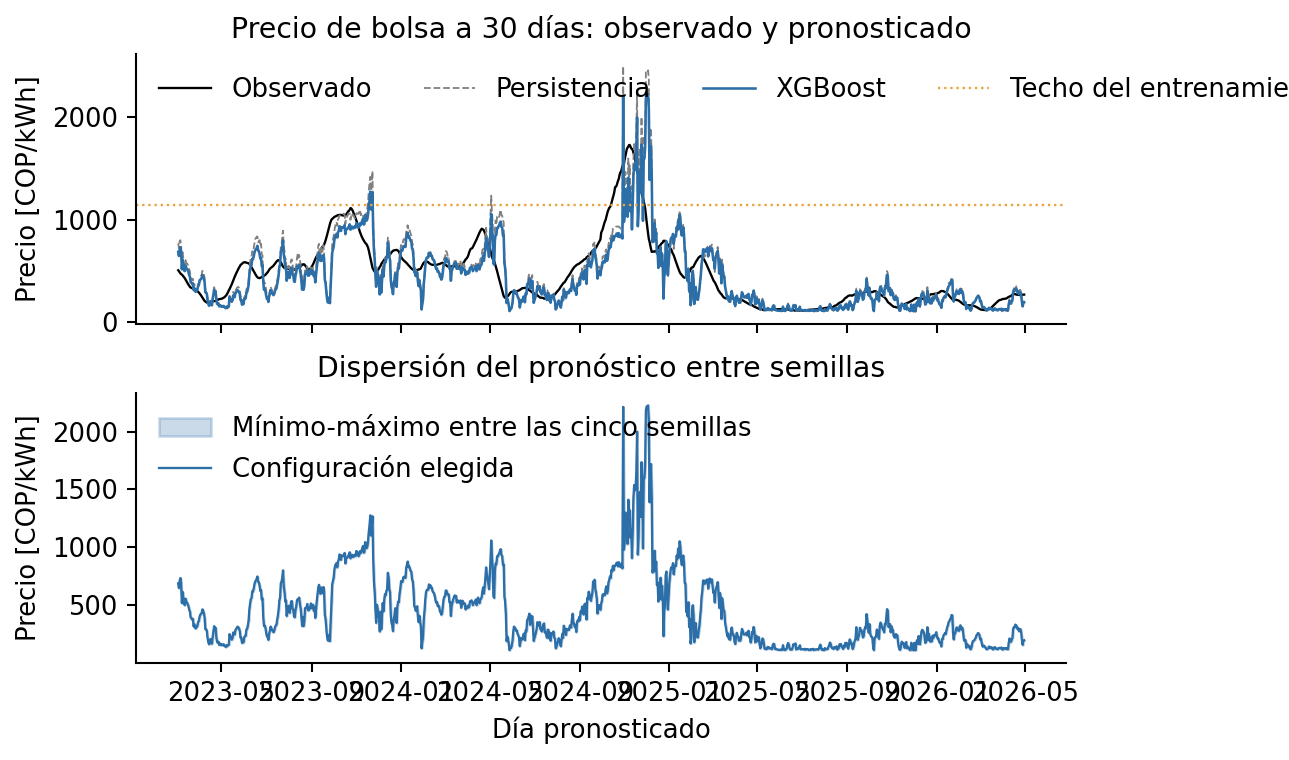

Techo del entrenamiento: 1147.9 COP/kWh
El pronóstico llega a 2226 COP/kWh y supera ese techo en 35 de los 1155 días pronosticados.
Amplitud media de la banda entre las cinco semillas: 2.1 COP/kWh


In [21]:
# ============================================================
# 10. El pronóstico sobre el periodo de prueba
# ============================================================
# ESTA ES LA FIGURA QUE VA AL DOCUMENTO, y la dibuja `_figuras.pronostico`, que es el mismo código
# para las cinco familias. Si cada cuaderno la dibujara por su cuenta, a la primera corrección en
# uno solo de ellos las figuras dejarían de ser comparables sin que nada avisara, y comparar
# familias es justamente lo que el trabajo hace.
#
# NO SE REENTRENA NI SE LEE NADA: se dibuja `pred_guardar`, que es lo que la celda anterior acaba
# de guardar como el archivo de predicciones. El techo del entrenamiento sí se lee del dataset de
# selección, para que las cinco familias marquen exactamente la misma línea.
from _figuras import pronostico, techo_entrenamiento, PROPORCION_PRONOSTICO

TECHO = techo_entrenamiento(PROC, FIN_ENTRENAMIENTO)
# La configuración publicada, localizada por su nombre y no por su posición: la de la
# TRAYECTORIA, que es la que registran las tres lecturas y la que publica el documento. Las
# columnas de semilla que la acompañan son las suyas, no las del estimador directo.
COL_PUB = next(c for c in pred_guardar.columns
               if "trayectoria" in c and "semilla_" not in c)
fig, datos = pronostico(pred_guardar, COL_PUB, "trayectoria_semilla_", "XGBoost", TECHO,
                        a_escala, ANCHO_PAGINA, alto_pagina(*PROPORCION_PRONOSTICO))
plt.show();

print(f"Techo del entrenamiento: {datos['techo']:.1f} COP/kWh")
print(f"El pronóstico llega a {datos['maximo_pronosticado']:.0f} COP/kWh y supera ese techo en "
      f"{datos['dias_sobre_techo']} de los {len(pred_guardar)} días pronosticados.")
print(f"Amplitud media de la banda entre las cinco semillas: {datos['amplitud_banda']:.1f} COP/kWh")

## 11. Conclusiones y limitaciones

### Qué se obtuvo

El XGBoost **supera a la persistencia** en las tres fases ENSO y en los cuatro años del periodo de prueba, con una mejora en MAE del **1,76 %** en el protocolo del trabajo (MAE 143,10 frente a 145,66) y del **3,18 %**….

### Las tres lecturas

| | `pares_30d` | `promedio_30d` | `dia_30` |
|---|---:|---:|---:|
| Persistencia | 178,37 | 145,66 | 239,27 |
| XGBoost (trayectoria, 5 semillas) | 175,59 | 143,17 | 232,74 |
| razón | 0,98 | 0,98 | 0,97 |

El orden frente a la persistencia **no depende de la lectura**, que es lo que hace utilizable la comparación.

### Cuatro hallazgos que conviene llevar al documento

1. **El objetivo en nivel es inviable para un modelo de árboles en esta serie.** Su pronóstico no pasa de **557 COP/kWh** cuando el promedio observado llega a 1.730, y arrastra un sesgo de **−146,8**.

 **Pero el MAE no siempre delata este defecto, y es la lección que hay que llevar al documento.** Medida contra un objetivo **puntual** —el precio de un solo día— esta misma variante puede dar **mejor** MAE que la relativa y ser igual de inservible: con pérdida absoluta el modelo persigue la mediana condicional y, en una distribución con cola derecha, quedarse corto sale barato. El promedio de la ventana premia menos ese sesgo y por eso aquí el MAE basta para rechazarla, pero lo que delata el techo en los dos casos es el **sesgo** y el **máximo del pronóstico**. La regla general: no elegir por MAE solo.

2. **Reajustar cada 60 días no ayuda a este modelo; lo empeora.**
3. **La configuración habitual de la literatura es la peor de la rejilla.** Profundidad 6, 400 árboles y pérdida cuadrática queda última y **por debajo de la persistencia**.

 Que el ganador sea tan poco flexible es coherente con el objetivo: promediar treinta días suaviza la serie y debilita la señal que queda por encima de la persistencia. Con 38 predictoras ya depuradas y una serie de 5.754 observaciones, la capacidad sobra y lo que escasea es señal.

4. **Las variables exógenas no mejoran el pronóstico de este modelo.** Entrenar solo con las columnas derivadas del precio deja el MAE en **142,94** frente a 143,10 con las 38: una diferencia de 0,16 COP/kWh, por debajo de la dispersión entre semillas y….

 Esto **no afecta** el compromiso del trabajo de evaluar segmentando por fase ENSO: ese es un criterio de *lectura de los resultados*, y la sección 8.5 muestra que la fase discrimina con fuerza el desempeño de todos los modelos, incluida la persistencia. El índice ONI se conserva en el dataset **fuera de las predictoras**, precisamente para poder etiquetar el régimen; no pasó la regla de selección del notebook 4 y no entra a ningún modelo. Queda por ver si las redes recurrentes, que pueden representar la interacción entre régimen climático y dinámica del precio de otra manera, le sacan algo más.

### Una observación sobre el horizonte

La curva de la sección 8.6 no tiene la forma que cabría esperar.

### Limitaciones que conviene declarar

- **El conjunto de variables lo decidió otro modelo.**
- **No hay búsqueda exhaustiva de hiperparámetros.**
- **La trayectoria cuesta 150 corridas de validación progresiva**
- **No se produce pronóstico probabilístico.**

### Archivos generados

`6_metricas_xgboost.csv`, `6_predicciones_xgboost.csv`, `6_error_por_horizonte_xgb.csv`, `6_importancia_xgboost.csv`, filas en `resultados_modelos.csv` y `models/baseline/XGBoost/xgboost_base.json`.

### Siguiente paso

Las tres familias que faltan —LSTM, GRU y el BiLSTM con atención y descomposición— sobre el mismo conjunto, la misma partición y el mismo registro, **entregando los treinta valores** para que las tres lecturas se puedan calcular con `lecturas()`.